In [1]:
import pandas as pd

In [2]:
df=pd.read_csv(r"C:\Users\pious\Downloads\players_data-2024_2025.csv")
df1=df.copy()
df1

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,...,Att (GK),Thr,Launch%,AvgLen,Opp,Stp,Stp%,#OPA,#OPA/90,AvgDist
0,1,Max Aarons,eng ENG,DF,Bournemouth,eng Premier League,24.0,2000.0,3,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Max Aarons,eng ENG,"DF,MF",Valencia,es La Liga,24.0,2000.0,4,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Rodrigo Abajas,es ESP,DF,Valencia,es La Liga,21.0,2003.0,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,James Abankwah,ie IRL,"DF,MF",Udinese,it Serie A,20.0,2004.0,6,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Keyliane Abdallah,fr FRA,FW,Marseille,fr Ligue 1,18.0,2006.0,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2849,2850,Edhy Zuliani,fr FRA,DF,Toulouse,fr Ligue 1,19.0,2004.0,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2850,2851,Szymon Żurkowski,pl POL,MF,Empoli,it Serie A,26.0,1997.0,5,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2851,2852,Martin Ødegaard,no NOR,MF,Arsenal,eng Premier League,25.0,1998.0,30,26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2852,2853,Milan Đurić,ba BIH,FW,Monza,it Serie A,34.0,1990.0,18,13,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
df1.shape

(2854, 184)

In [4]:
df1 = df1.drop(columns=["Rk"], errors="ignore")

In [7]:
df1 = df1.loc[
    :,
    ~df1.columns.str.match(
        r'^(Rk|Nation|Pos|Comp|Age|Born|90s)_stats_'
    )
]

In [9]:
goalkeeping_cols = [
    col for col in df1.columns
    if "_stats_goalkeeping" in col
    or "_stats_keeper" in col
    or "_stats_gk" in col
]

df1 = df1.drop(columns=goalkeeping_cols, errors="ignore")

In [12]:
print("Shape:", df1.shape)
print("Number of columns:", len(df1.columns))

Shape: (2854, 184)
Number of columns: 184


In [16]:
print(len(df1.columns))
print(df1.columns.tolist())

123
['Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'xG', 'npxG', 'xAG', 'npxG+xAG', 'PrgC', 'PrgP', 'PrgR', 'G+A-PK', 'xG+xAG', 'Gls_stats_shooting', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'Dist', 'FK', 'PK_stats_shooting', 'PKatt_stats_shooting', 'xG_stats_shooting', 'npxG_stats_shooting', 'npxG/Sh', 'G-xG', 'np:G-xG', 'Cmp', 'Att', 'Cmp%', 'TotDist', 'PrgDist', 'Ast_stats_passing', 'xAG_stats_passing', 'xA', 'A-xAG', 'KP', '1/3', 'PPA', 'CrsPA', 'PrgP_stats_passing', 'Att_stats_passing_types', 'Live', 'Dead', 'FK_stats_passing_types', 'TB', 'Sw', 'Crs', 'TI', 'CK', 'In', 'Out', 'Str', 'Cmp_stats_passing_types', 'Off', 'Blocks', 'SCA', 'SCA90', 'PassLive', 'PassDead', 'TO', 'Sh_stats_gca', 'Fld', 'Def', 'GCA', 'GCA90', 'Tkl', 'TklW', 'Def 3rd', 'Mid 3rd', 'Att 3rd', 'Att_stats_defense', 'Tkl%', 'Lost', 'Blocks_stats_defense', 'Sh_stats_defense', 'Pass', 'Int', 'Tkl+

In [14]:
# ==========================================
# FOOTBALL INTELLIGENCE ENGINE
# 184 → 120 ESSENTIAL COLUMNS
# ==========================================

# Goalkeeping-specific metrics
# We are building an outfield-player intelligence model,
# so goalkeeper-only metrics are removed.

goalkeeping_cols = [
    'GA',
    'GA90',
    'SoTA',
    'Saves',
    'Save%',
    'W',
    'D',
    'L',
    'CS',
    'CS%',
    'PKA',
    'PKsv',
    'PKm',
    'PSxG',
    'PSxG/SoT',
    'PSxG+/-',
    '/90',
    'Att (GK)',
    'Thr',
    'Launch%',
    'AvgLen',
    'Opp',
    'Stp',
    'Stp%',
    '#OPA',
    '#OPA/90',
    'AvgDist'
]


# Playing-time metrics that are redundant
# We already retain MP, Starts, Min and 90s.

playing_time_cols = [
    'MP_stats_playing_time',
    'Min_stats_playing_time',
    'Mn/MP',
    'Min%',
    'Starts_stats_playing_time',
    'Mn/Start',
    'Compl',
    'Subs',
    'Mn/Sub',
    'unSub',
    'PPM',
    'onG',
    'onGA',
    '+/-',
    '+/-90',
    'On-Off',
    'onxG',
    'onxGA',
    'xG+/-',
    'xG+/-90'
]


# Miscellaneous metrics that are either duplicated
# elsewhere or not essential to our core player profiling.

misc_cols = [
    'CrdY_stats_misc',
    'CrdR_stats_misc',
    '2CrdY',
    'Fls',
    'Fld_stats_misc',
    'Off_stats_misc',
    'Crs_stats_misc',
    'Int_stats_misc',
    'TklW_stats_misc',
    'PKwon',
    'PKcon',
    'OG',
    'Recov',
    'Lost_stats_misc'
]


# Combine columns
columns_to_drop = (
    goalkeeping_cols
    + playing_time_cols
    + misc_cols
)


# Drop
df1 = df1.drop(
    columns=columns_to_drop,
    errors='ignore'
)


# Check
print("Number of columns:", len(df1.columns))
print("Shape:", df1.shape)

Number of columns: 123
Shape: (2854, 123)


In [15]:
df1.shape

(2854, 123)

In [17]:
df_clean = df1.copy()

print("Final cleaned dataset:")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

Final cleaned dataset:
Rows: 2854
Columns: 123


In [18]:
df_backup = df_clean.copy()

In [19]:
# Create primary position group

def assign_position(pos):
    if pd.isna(pos):
        return np.nan
    
    primary = pos.split(',')[0]
    
    if primary == 'FW':
        return 'Forward'
    elif primary == 'MF':
        return 'Midfielder'
    elif primary == 'DF':
        return 'Defender'
    elif primary == 'GK':
        return 'Goalkeeper'
    else:
        return np.nan


df_clean['Position_Group'] = df_clean['Pos'].apply(assign_position)

print(df_clean['Position_Group'].value_counts(dropna=False))

Position_Group
Defender      1022
Midfielder     900
Forward        720
Goalkeeper     212
Name: count, dtype: int64


In [20]:
df_forwards = df_clean[df_clean['Position_Group'] == 'Forward'].copy()

df_midfielders = df_clean[df_clean['Position_Group'] == 'Midfielder'].copy()

df_defenders = df_clean[df_clean['Position_Group'] == 'Defender'].copy()

df_goalkeepers = df_clean[df_clean['Position_Group'] == 'Goalkeeper'].copy()

In [21]:
print("Forwards:", df_forwards.shape)
print("Midfielders:", df_midfielders.shape)
print("Defenders:", df_defenders.shape)
print("Goalkeepers:", df_goalkeepers.shape)

Forwards: (720, 124)
Midfielders: (900, 124)
Defenders: (1022, 124)
Goalkeepers: (212, 124)


In [22]:
# Identify players who have more than one listed position

df_clean['Is_Multi_Position'] = df_clean['Pos'].str.contains(',', na=False)

print(df_clean['Is_Multi_Position'].value_counts())

Is_Multi_Position
False    2031
True      823
Name: count, dtype: int64


In [23]:
# Multi-position players
df_multi = df_clean[df_clean['Is_Multi_Position'] == True].copy()

# Single-position players
df_single = df_clean[df_clean['Is_Multi_Position'] == False].copy()

In [24]:
df_forwards = df_single[df_single['Pos'] == 'FW'].copy()

df_midfielders = df_single[df_single['Pos'] == 'MF'].copy()

df_defenders = df_single[df_single['Pos'] == 'DF'].copy()

df_goalkeepers = df_single[df_single['Pos'] == 'GK'].copy()

In [25]:
print("Forwards:", df_forwards.shape)
print("Midfielders:", df_midfielders.shape)
print("Defenders:", df_defenders.shape)
print("Goalkeepers:", df_goalkeepers.shape)
print("Multi-position:", df_multi.shape)

Forwards: (371, 125)
Midfielders: (589, 125)
Defenders: (859, 125)
Goalkeepers: (212, 125)
Multi-position: (823, 125)


In [26]:
print(df_multi['Pos'].value_counts())

Pos
FW,MF    325
MF,FW    230
DF,MF    110
MF,DF     81
DF,FW     53
FW,DF     24
Name: count, dtype: int64


In [27]:
print(df_multi['Pos'].value_counts())

Pos
FW,MF    325
MF,FW    230
DF,MF    110
MF,DF     81
DF,FW     53
FW,DF     24
Name: count, dtype: int64


In [29]:
#COMMON METADATA COLUMNS

common_cols = [
    'Player',
    'Nation',
    'Pos',
    'Squad',
    'Comp',
    'Age',
    'Born',
    'MP',
    'Starts',
    'Min',
    '90s'
]

In [30]:
forward_cols = common_cols + [

    # ===== ATTACKING OUTPUT =====
    'Gls',
    'Ast',
    'G+A',
    'G-PK',
    'PK',
    'PKatt',
    'xG',
    'npxG',
    'xAG',
    'npxG+xAG',
    'G+A-PK',
    'xG+xAG',

    # ===== SHOOTING / FINISHING =====
    'Sh',
    'SoT',
    'SoT%',
    'Sh/90',
    'SoT/90',
    'G/Sh',
    'G/SoT',
    'Dist',
    'FK',
    'npxG/Sh',
    'G-xG',
    'np:G-xG',

    # ===== PASSING / CREATION =====
    'Cmp',
    'Att',
    'Cmp%',
    'xA',
    'A-xAG',
    'KP',
    'PPA',
    'CrsPA',
    'PrgP',

    # ===== CHANCE CREATION =====
    'SCA',
    'SCA90',
    'PassLive',
    'PassDead',
    'TO',
    'GCA',
    'GCA90',

    # ===== PROGRESSION =====
    'PrgC',
    'PrgR',

    # ===== BALL CARRYING / 1v1 =====
    'Touches',
    'Att Pen',
    'Succ',
    'Succ%',
    'Tkld',
    'Tkld%',
    'Carries',
    'CPA',
    'Mis',
    'Dis',
    'Rec',

    # ===== AERIAL =====
    'Won',
    'Won%'
]

In [31]:
midfielder_cols = common_cols + [

    # ===== ATTACKING OUTPUT =====
    'Gls',
    'Ast',
    'G+A',
    'G-PK',
    'xG',
    'npxG',
    'xAG',
    'npxG+xAG',
    'G+A-PK',
    'xG+xAG',

    # ===== SHOOTING =====
    'Sh',
    'SoT',
    'SoT%',
    'Sh/90',
    'SoT/90',
    'G/Sh',
    'npxG/Sh',
    'G-xG',

    # ===== PASSING =====
    'Cmp',
    'Att',
    'Cmp%',
    'TotDist',
    'PrgDist',
    'xA',
    'A-xAG',
    'KP',
    '1/3',
    'PPA',
    'CrsPA',
    'PrgP',

    # ===== PASSING TYPES =====
    'Live',
    'Dead',
    'TB',
    'Sw',
    'Crs',
    'TI',
    'CK',
    'In',
    'Out',
    'Str',

    # ===== CHANCE CREATION =====
    'SCA',
    'SCA90',
    'PassLive',
    'PassDead',
    'TO',
    'GCA',
    'GCA90',

    # ===== DEFENSIVE CONTRIBUTION =====
    'Tkl',
    'TklW',
    'Def 3rd',
    'Mid 3rd',
    'Att 3rd',
    'Tkl%',
    'Lost',
    'Pass',
    'Int',
    'Tkl+Int',
    'Blocks',
    'Clr',

    # ===== POSSESSION =====
    'Touches',
    'Def Pen',
    'Att Pen',
    'Succ',
    'Succ%',
    'Tkld',
    'Tkld%',
    'Carries',
    'CPA',
    'Mis',
    'Dis',
    'Rec',

    # ===== PROGRESSION =====
    'PrgC',
    'PrgR'
]

In [32]:
defender_cols = common_cols + [

    # ===== DEFENSIVE ACTIONS =====
    'Tkl',
    'TklW',
    'Def 3rd',
    'Mid 3rd',
    'Att 3rd',
    'Tkl%',
    'Lost',
    'Blocks',
    'Pass',
    'Int',
    'Tkl+Int',
    'Clr',
    'Err',

    # ===== AERIAL =====
    'Won',
    'Won%',

    # ===== PASSING / BUILD-UP =====
    'Cmp',
    'Att',
    'Cmp%',
    'TotDist',
    'PrgDist',
    'xA',
    'A-xAG',
    '1/3',
    'PPA',
    'CrsPA',
    'PrgP',

    # ===== PASSING TYPES =====
    'Live',
    'Dead',
    'TB',
    'Sw',
    'Crs',
    'TI',
    'Str',

    # ===== POSSESSION =====
    'Touches',
    'Def Pen',
    'Att Pen',
    'Carries',
    'Rec',
    'Mis',
    'Dis',

    # ===== PROGRESSION / CARRYING =====
    'PrgC',
    'CPA',
    'Succ',
    'Succ%',
    'Tkld',
    'Tkld%',

    # ===== ATTACKING CONTRIBUTION =====
    'Gls',
    'Ast',
    'xG',
    'xAG'
]

In [33]:
multi_cols = list(dict.fromkeys(
    forward_cols +
    midfielder_cols +
    defender_cols
))

In [34]:
df_forwards = df_single[
    df_single['Pos'] == 'FW'
][forward_cols].copy()

df_midfielders = df_single[
    df_single['Pos'] == 'MF'
][midfielder_cols].copy()

df_defenders = df_single[
    df_single['Pos'] == 'DF'
][defender_cols].copy()

df_multi_position = df_multi[
    multi_cols
].copy()

In [35]:
print("FORWARDS")
print(df_forwards.shape)

print("\nMIDFIELDERS")
print(df_midfielders.shape)

print("\nDEFENDERS")
print(df_defenders.shape)

print("\nMULTI-POSITION")
print(df_multi_position.shape)

FORWARDS
(371, 66)

MIDFIELDERS
(589, 84)

DEFENDERS
(859, 61)

MULTI-POSITION
(823, 93)


In [36]:
print("\nMissing Forward columns:")
print(set(forward_cols) - set(df_clean.columns))

print("\nMissing Midfielder columns:")
print(set(midfielder_cols) - set(df_clean.columns))

print("\nMissing Defender columns:")
print(set(defender_cols) - set(df_clean.columns))


Missing Forward columns:
set()

Missing Midfielder columns:
set()

Missing Defender columns:
set()


In [37]:
print("Master dataset:", df_clean.shape)
print("Forwards:", df_forwards.shape)
print("Midfielders:", df_midfielders.shape)
print("Defenders:", df_defenders.shape)
print("Multi-position:", df_multi_position.shape)

Master dataset: (2854, 125)
Forwards: (371, 66)
Midfielders: (589, 84)
Defenders: (859, 61)
Multi-position: (823, 93)


In [38]:
# Save all 5 datasets

df_clean.to_csv("football_master_clean.csv", index=False)
df_forwards.to_csv("football_forwards.csv", index=False)
df_midfielders.to_csv("football_midfielders.csv", index=False)
df_defenders.to_csv("football_defenders.csv", index=False)
df_multi_position.to_csv("football_multi_position.csv", index=False)

print("All 5 datasets saved successfully!")

All 5 datasets saved successfully!


In [39]:
# ==========================================
# POSITION DATASET OVERVIEW
# ==========================================

datasets = {
    "Forwards": df_forwards,
    "Midfielders": df_midfielders,
    "Defenders": df_defenders,
    "Multi-position": df_multi_position
}

for name, data in datasets.items():
    print(f"\n{'='*50}")
    print(name)
    print(f"{'='*50}")
    print("Rows:", data.shape[0])
    print("Columns:", data.shape[1])
    print("Missing values:", data.isna().sum().sum())


Forwards
Rows: 371
Columns: 66
Missing values: 421

Midfielders
Rows: 589
Columns: 84
Missing values: 474

Defenders
Rows: 859
Columns: 61
Missing values: 374

Multi-position
Rows: 823
Columns: 93
Missing values: 513


In [40]:
for name, data in datasets.items():
    print(f"{name}: {len(data)} players")

Forwards: 371 players
Midfielders: 589 players
Defenders: 859 players
Multi-position: 823 players


In [41]:
for name, data in datasets.items():
    print(f"\n{name}")
    print(data['Min'].describe())


Forwards
count     371.000000
mean     1025.016173
std       927.164777
min         1.000000
25%       167.500000
50%       790.000000
75%      1764.000000
max      3414.000000
Name: Min, dtype: float64

Midfielders
count     589.000000
mean     1180.349745
std       960.548830
min         1.000000
25%       257.000000
50%      1045.000000
75%      1967.000000
max      3271.000000
Name: Min, dtype: float64

Defenders
count     859.000000
mean     1369.860303
std       982.369545
min         1.000000
25%       464.000000
50%      1234.000000
75%      2189.500000
max      3420.000000
Name: Min, dtype: float64

Multi-position
count     823.000000
mean     1081.811665
std       860.229164
min         2.000000
25%       301.000000
50%       951.000000
75%      1735.000000
max      3351.000000
Name: Min, dtype: float64


In [42]:
missing_fw = (
    df_forwards.isna()
    .sum()
    .sort_values(ascending=False)
)

missing_fw[missing_fw > 0]

G/SoT      80
npxG/Sh    49
SoT%       49
G/Sh       49
Dist       49
Tkld%      47
Succ%      47
Won%       38
Cmp%        8
Born        2
Age         2
Nation      1
dtype: int64

In [43]:
for name, data in datasets.items():
    
    print(f"\n{'='*60}")
    print(name)
    print(f"{'='*60}")
    
    missing = data.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    
    print(missing)


Forwards
G/SoT      80
SoT%       49
G/Sh       49
Dist       49
npxG/Sh    49
Succ%      47
Tkld%      47
Won%       38
Cmp%        8
Age         2
Born        2
Nation      1
dtype: int64

Midfielders
SoT%       83
G/Sh       83
npxG/Sh    83
Succ%      72
Tkld%      72
Tkl%       70
Cmp%        6
Nation      3
Age         1
Born        1
dtype: int64

Defenders
Succ%     128
Tkld%     128
Tkl%       63
Won%       46
Cmp%        4
Age         2
Born        2
Nation      1
dtype: int64

Multi-position
G/SoT      143
Tkl%        57
SoT%        52
G/Sh        52
Dist        52
npxG/Sh     52
Succ%       33
Tkld%       33
Won%        30
Age          3
Born         3
Nation       2
Cmp%         1
dtype: int64


In [44]:
print("FORWARD MISSING-VALUE CHECK")
print("--------------------------------")

print("Missing G/SoT:", df_forwards['G/SoT'].isna().sum())
print("Players with SoT = 0:", (df_forwards['SoT'] == 0).sum())

print("\nMissing G/Sh:", df_forwards['G/Sh'].isna().sum())
print("Players with Sh = 0:", (df_forwards['Sh'] == 0).sum())

print("\nMissing SoT%:", df_forwards['SoT%'].isna().sum())
print("Players with Sh = 0:", (df_forwards['Sh'] == 0).sum())

print("\nMissing npxG/Sh:", df_forwards['npxG/Sh'].isna().sum())
print("Players with Sh = 0:", (df_forwards['Sh'] == 0).sum())

print("\nMissing Succ%:", df_forwards['Succ%'].isna().sum())
print("Players with Succ = 0:", (df_forwards['Succ'] == 0).sum())

print("\nMissing Won%:", df_forwards['Won%'].isna().sum())
print("Players with Won = 0:", (df_forwards['Won'] == 0).sum())

FORWARD MISSING-VALUE CHECK
--------------------------------
Missing G/SoT: 80
Players with SoT = 0: 80

Missing G/Sh: 49
Players with Sh = 0: 49

Missing SoT%: 49
Players with Sh = 0: 49

Missing npxG/Sh: 49
Players with Sh = 0: 49

Missing Succ%: 47
Players with Succ = 0: 71

Missing Won%: 38
Players with Won = 0: 63


In [45]:
for name, data in datasets.items():
    print(f"\n{name}")
    print("Under 90 min:", (data['Min'] < 90).sum())
    print("Under 450 min:", (data['Min'] < 450).sum())
    print("Under 900 min:", (data['Min'] < 900).sum())


Forwards
Under 90 min: 79
Under 450 min: 144
Under 900 min: 198

Midfielders
Under 90 min: 106
Under 450 min: 187
Under 900 min: 265

Defenders
Under 90 min: 72
Under 450 min: 212
Under 900 min: 327

Multi-position
Under 90 min: 88
Under 450 min: 272
Under 900 min: 402


In [46]:
MIN_MINUTES = 450

df_forwards_ml = df_forwards[
    df_forwards['Min'] >= MIN_MINUTES
].copy()

df_midfielders_ml = df_midfielders[
    df_midfielders['Min'] >= MIN_MINUTES
].copy()

df_defenders_ml = df_defenders[
    df_defenders['Min'] >= MIN_MINUTES
].copy()

df_multi_position_ml = df_multi_position[
    df_multi_position['Min'] >= MIN_MINUTES
].copy()

In [47]:
print("Forwards:", df_forwards_ml.shape)
print("Midfielders:", df_midfielders_ml.shape)
print("Defenders:", df_defenders_ml.shape)
print("Multi-position:", df_multi_position_ml.shape)

Forwards: (227, 66)
Midfielders: (402, 84)
Defenders: (647, 61)
Multi-position: (551, 93)


In [49]:
# Check percentage metrics relevant to FORWARDS

checks_forward = {
    'Cmp%': 'Att',
    'Succ%': 'Succ',
    'Won%': 'Won'
}

for name, related_col in checks_forward.items():
    print(f"\n{name}")
    print("Missing:", df_forwards[name].isna().sum())
    print(f"{related_col} = 0:", (df_forwards[related_col] == 0).sum())


Cmp%
Missing: 8
Att = 0: 8

Succ%
Missing: 47
Succ = 0: 71

Won%
Missing: 38
Won = 0: 63


In [50]:
df_forwards_ml.to_csv("football_forwards_ml.csv", index=False)
df_midfielders_ml.to_csv("football_midfielders_ml.csv", index=False)
df_defenders_ml.to_csv("football_defenders_ml.csv", index=False)
df_multi_position_ml.to_csv("football_multi_position_ml.csv", index=False)

print("ML-ready datasets saved.")

ML-ready datasets saved.


In [51]:
def add_per90_features(df, count_columns):
    
    df = df.copy()
    
    for col in count_columns:
        if col in df.columns:
            df[f'{col}_p90'] = df[col] / df['90s']
    
    return df

In [52]:
forward_p90_cols = [
    'Gls',
    'Ast',
    'G+A',
    'G-PK',
    'PK',
    'PKatt',
    'xG',
    'npxG',
    'xAG',
    'npxG+xAG',
    'G+A-PK',
    'xG+xAG',
    
    'Sh',
    'SoT',
    'FK',
    
    'Cmp',
    'Att',
    'TotDist',
    'PrgDist',
    'KP',
    '1/3',
    'PPA',
    'CrsPA',
    'PrgP',
    
    'Live',
    'Dead',
    'TB',
    'Sw',
    'Crs',
    'TI',
    'CK',
    'In',
    'Out',
    'Str',
    'Off',
    'Blocks',
    
    'SCA',
    'PassLive',
    'PassDead',
    'TO',
    'Fld',
    'Def',
    'GCA',
    
    'PrgC',
    'PrgR',
    
    'Touches',
    'Att Pen',
    'Succ',
    'Tkld',
    'Carries',
    'CPA',
    'Mis',
    'Dis',
    'Rec',
    
    'Won'
]

In [53]:
midfielder_p90_cols = [
    'Gls',
    'Ast',
    'G+A',
    'G-PK',
    'xG',
    'npxG',
    'xAG',
    'npxG+xAG',
    'G+A-PK',
    'xG+xAG',
    
    'Sh',
    'SoT',
    
    'Cmp',
    'Att',
    'TotDist',
    'PrgDist',
    'KP',
    '1/3',
    'PPA',
    'CrsPA',
    'PrgP',
    
    'Live',
    'Dead',
    'TB',
    'Sw',
    'Crs',
    'TI',
    'CK',
    'In',
    'Out',
    'Str',
    
    'SCA',
    'PassLive',
    'PassDead',
    'TO',
    'Fld',
    'GCA',
    
    'Tkl',
    'TklW',
    'Def 3rd',
    'Mid 3rd',
    'Att 3rd',
    'Lost',
    'Pass',
    'Int',
    'Tkl+Int',
    'Blocks',
    'Clr',
    
    'Touches',
    'Def Pen',
    'Att Pen',
    'Succ',
    'Tkld',
    'Carries',
    'CPA',
    'Mis',
    'Dis',
    'Rec',
    
    'PrgC',
    'PrgR'
]

In [54]:
defender_p90_cols = [
    'Tkl',
    'TklW',
    'Def 3rd',
    'Mid 3rd',
    'Att 3rd',
    'Lost',
    'Blocks',
    'Pass',
    'Int',
    'Tkl+Int',
    'Clr',
    'Err',
    
    'Won',
    
    'Cmp',
    'Att',
    'TotDist',
    'PrgDist',
    'KP',
    '1/3',
    'PPA',
    'CrsPA',
    'PrgP',
    
    'Live',
    'Dead',
    'TB',
    'Sw',
    'Crs',
    'TI',
    'Str',
    
    'Touches',
    'Def Pen',
    'Att Pen',
    'Carries',
    'Rec',
    'Mis',
    'Dis',
    
    'PrgC',
    'CPA',
    'Succ',
    'Tkld',
    
    'Gls',
    'Ast',
    'xG',
    'xAG'
]

In [55]:
df_forwards_ml = add_per90_features(
    df_forwards_ml,
    forward_p90_cols
)

df_midfielders_ml = add_per90_features(
    df_midfielders_ml,
    midfielder_p90_cols
)

df_defenders_ml = add_per90_features(
    df_defenders_ml,
    defender_p90_cols
)

In [56]:
multi_p90_cols = list(dict.fromkeys(
    forward_p90_cols +
    midfielder_p90_cols +
    defender_p90_cols
))

df_multi_position_ml = add_per90_features(
    df_multi_position_ml,
    multi_p90_cols
)

In [57]:
print("Forwards:", df_forwards_ml.shape)
print("Midfielders:", df_midfielders_ml.shape)
print("Defenders:", df_defenders_ml.shape)
print("Multi-position:", df_multi_position_ml.shape)

Forwards: (227, 104)
Midfielders: (402, 143)
Defenders: (647, 104)
Multi-position: (551, 157)


In [60]:
import numpy as np

In [62]:
# Select only numerical columns
fw_numeric = df_forwards_ml.select_dtypes(include=np.number)

# Correlation matrix
fw_corr = fw_numeric.corr()

fw_corr

,Age,Born,MP,Starts,Min,90s,Gls,Ast,G+A,G-PK,...,Touches_p90,Att Pen_p90,Succ_p90,Tkld_p90,Carries_p90,CPA_p90,Mis_p90,Dis_p90,Rec_p90,Won_p90
Age,1.000000,-0.992954,0.068661,0.036851,0.050108,0.050283,0.125088,0.091473,0.129563,0.076459,...,-0.069513,-0.034943,-0.235296,-0.323920,-0.128985,-0.236719,-0.239777,-0.231634,-0.058036,0.138868
Born,-0.992954,1.000000,-0.074625,-0.037152,-0.052147,-0.052283,-0.131692,-0.087157,-0.133258,-0.084533,...,0.080877,0.032950,0.248397,0.331307,0.139024,0.239512,0.237322,0.222992,0.069186,-0.137263
MP,0.068661,-0.074625,1.000000,0.785671,0.835252,0.835276,0.561064,0.471928,0.601919,0.564464,...,0.032674,0.104769,0.051304,-0.032199,0.026726,0.099333,-0.050872,-0.106390,0.037167,-0.056333
Starts,0.036851,-0.037152,0.785671,1.000000,0.985440,0.985432,0.706469,0.565305,0.747977,0.698277,...,0.031528,0.114564,0.103345,0.021109,0.062873,0.154914,-0.058043,-0.090468,0.045923,-0.185775
Min,0.050108,-0.052147,0.835252,0.985440,1.000000,0.999994,0.721457,0.582377,0.765590,0.712385,...,0.042731,0.139907,0.115703,0.026757,0.069876,0.163647,-0.057863,-0.094652,0.057925,-0.156922
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CPA_p90,-0.236719,0.239512,0.099333,0.154914,0.163647,0.163518,0.156817,0.447262,0.276541,0.173409,...,0.693567,0.549425,0.746823,0.748764,0.786339,1.000000,0.049230,0.150652,0.718908,-0.470830
Mis_p90,-0.239777,0.237322,-0.050872,-0.058043,-0.057863,-0.057978,-0.003037,-0.118493,-0.043075,0.016374,...,-0.002461,0.127078,0.153683,0.167967,0.024734,0.049230,1.000000,0.479655,0.032726,0.214282
Dis_p90,-0.231634,0.222992,-0.106390,-0.090468,-0.094652,-0.094561,-0.097421,-0.068651,-0.099950,-0.077217,...,0.107212,0.090043,0.258965,0.341123,0.187560,0.150652,0.479655,1.000000,0.164041,0.002904
Rec_p90,-0.058036,0.069186,0.037167,0.045923,0.057925,0.057671,0.078654,0.396343,0.197778,0.082105,...,0.961752,0.450170,0.708147,0.623297,0.960502,0.718908,0.032726,0.164041,1.000000,-0.315865


In [63]:
# Find highly correlated feature pairs

corr_pairs = (
    fw_corr
    .where(np.triu(np.ones(fw_corr.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)

high_corr_fw = corr_pairs[abs(corr_pairs) >= 0.85]

print(high_corr_fw)

Min     90s        0.999994
Sh/90   Sh_p90     0.999968
SoT/90  SoT_p90    0.999950
GCA90   GCA_p90    0.999787
SCA90   SCA_p90    0.999653
                     ...   
xA      Rec        0.854008
Cmp     PrgC       0.851112
xAG     Cmp        0.850205
Succ%   Tkld%     -0.862697
Age     Born      -0.992954
Length: 169, dtype: float64


In [64]:
redundant_features = [
    'Born',

    # Duplicate of existing /90 metrics
    'Sh_p90',
    'SoT_p90',
    'SCA_p90',
    'GCA_p90'
]

In [65]:
# Find extremely high correlations
very_high_corr_fw = corr_pairs[abs(corr_pairs) >= 0.95]

print(very_high_corr_fw.to_string())

Min          90s             0.999994
Sh/90        Sh_p90          0.999968
SoT/90       SoT_p90         0.999950
GCA90        GCA_p90         0.999787
SCA90        SCA_p90         0.999653
Touches      Rec             0.987766
Cmp          Att             0.987514
Carries      Rec             0.986009
Starts       Min             0.985440
             90s             0.985432
Att          Touches         0.985310
G-xG         np:G-xG         0.981951
Att          Rec             0.978175
Touches      Carries         0.977932
Gls          G-PK            0.975994
xG           npxG            0.975941
Att          Carries         0.973433
Cmp_p90      Att_p90         0.972921
SCA          PassLive        0.972499
Att_p90      Touches_p90     0.971834
Cmp          Carries         0.971222
G+A-PK       G+A_p90         0.969488
PK           PKatt           0.968462
Cmp          Rec             0.967718
             Touches         0.964589
Touches_p90  Rec_p90         0.961752
xG+xAG      

In [66]:
forward_ml_features = [
    # Finishing / output
    'Gls_p90',
    'G-PK_p90',
    'xG_p90',
    'npxG_p90',
    'G-xG_p90',

    # Creation
    'Ast_p90',
    'xAG_p90',
    'xA_p90',
    'KP_p90',
    'SCA90',
    'GCA90',

    # Shooting
    'Sh/90',
    'SoT/90',
    'SoT%',
    'G/Sh',
    'npxG/Sh',

    # Progression / carrying
    'PrgC_p90',
    'PrgR_p90',
    'Carries_p90',
    'Succ%',
    'CPA_p90',
    'PPA_p90',

    # Attacking involvement
    'Touches_p90',
    'Att Pen_p90',
    'Rec_p90',

    # Aerial
    'Won_p90',
    'Won%'
]

In [67]:
midfielder_ml_features = [
    # Attacking
    'Gls_p90',
    'xG_p90',
    'Ast_p90',
    'xAG_p90',
    'xA_p90',

    # Passing
    'Cmp_p90',
    'Cmp%',
    'PrgP_p90',
    '1/3_p90',
    'KP_p90',
    'PPA_p90',
    'CrsPA_p90',

    # Chance creation
    'SCA90',
    'GCA90',

    # Progression
    'PrgC_p90',
    'PrgR_p90',

    # Possession / carrying
    'Touches_p90',
    'Carries_p90',
    'Succ%',
    'Rec_p90',

    # Defensive contribution
    'Tkl_p90',
    'TklW_p90',
    'Tkl%',
    'Int_p90',
    'Tkl+Int_p90',
    'Blocks_p90',
    'Lost_p90',

    # Aerial
    'Won_p90',
    'Won%'
]

In [68]:
defender_ml_features = [
    # Defending
    'Tkl_p90',
    'TklW_p90',
    'Tkl%',
    'Int_p90',
    'Tkl+Int_p90',
    'Blocks_p90',
    'Pass_p90',
    'Clr_p90',
    'Err_p90',

    # Aerial
    'Won_p90',
    'Won%',

    # Build-up / passing
    'Cmp_p90',
    'Cmp%',
    'PrgP_p90',
    '1/3_p90',
    'PPA_p90',
    'CrsPA_p90',

    # Possession
    'Touches_p90',
    'Def Pen_p90',
    'Att Pen_p90',
    'Carries_p90',
    'Succ%',
    'Rec_p90',

    # Progression
    'PrgC_p90',

    # Attacking contribution
    'Gls_p90',
    'Ast_p90',
    'xG_p90',
    'xAG_p90'
]

In [69]:
multi_ml_features = list(dict.fromkeys(
    forward_ml_features +
    midfielder_ml_features +
    defender_ml_features
))

In [70]:
df_forwards_candidate = df_forwards_ml[
    forward_ml_features
].copy()

df_midfielders_candidate = df_midfielders_ml[
    midfielder_ml_features
].copy()

df_defenders_candidate = df_defenders_ml[
    defender_ml_features
].copy()

df_multi_candidate = df_multi_position_ml[
    multi_ml_features
].copy()

KeyError: "['G-xG_p90', 'xA_p90'] not in index"

In [71]:
# Add the missing per-90 features

for df in [
    df_forwards_ml,
    df_midfielders_ml,
    df_defenders_ml,
    df_multi_position_ml
]:
    if 'xA' in df.columns:
        df['xA_p90'] = df['xA'] / df['90s']

    if 'G-xG' in df.columns:
        df['G-xG_p90'] = df['G-xG'] / df['90s']

In [72]:
print('xA_p90' in df_forwards_ml.columns)
print('G-xG_p90' in df_forwards_ml.columns)

print('xA_p90' in df_midfielders_ml.columns)
print('xA_p90' in df_defenders_ml.columns)

True
True
True
True


In [73]:
df_forwards_candidate = df_forwards_ml[
    forward_ml_features
].copy()

df_midfielders_candidate = df_midfielders_ml[
    midfielder_ml_features
].copy()

df_defenders_candidate = df_defenders_ml[
    defender_ml_features
].copy()

df_multi_candidate = df_multi_position_ml[
    multi_ml_features
].copy()

KeyError: "['Won_p90', 'Won%'] not in index"

In [74]:
print("Missing Forward features:")
print(set(forward_ml_features) - set(df_forwards_ml.columns))

print("\nMissing Midfielder features:")
print(set(midfielder_ml_features) - set(df_midfielders_ml.columns))

print("\nMissing Defender features:")
print(set(defender_ml_features) - set(df_defenders_ml.columns))

print("\nMissing Multi-position features:")
print(set(multi_ml_features) - set(df_multi_position_ml.columns))

Missing Forward features:
set()

Missing Midfielder features:
{'Won_p90', 'Won%'}

Missing Defender features:
set()

Missing Multi-position features:
set()


In [77]:
# Add aerial metrics for midfielders

df_midfielders_ml['Won_p90'] = (
    df_midfielders_ml['Won'] / df_midfielders_ml['90s']
)

KeyError: 'Won'

In [78]:
midfielder_ml_features = [
    # Attacking
    'Gls_p90',
    'xG_p90',
    'Ast_p90',
    'xAG_p90',
    'xA_p90',

    # Passing
    'Cmp_p90',
    'Cmp%',
    'PrgP_p90',
    '1/3_p90',
    'KP_p90',
    'PPA_p90',
    'CrsPA_p90',

    # Chance creation
    'SCA90',
    'GCA90',

    # Progression
    'PrgC_p90',
    'PrgR_p90',

    # Possession / carrying
    'Touches_p90',
    'Carries_p90',
    'Succ%',
    'Rec_p90',

    # Defensive contribution
    'Tkl_p90',
    'TklW_p90',
    'Tkl%',
    'Int_p90',
    'Tkl+Int_p90',
    'Blocks_p90',
    'Lost_p90'
]

In [79]:
df_midfielders_candidate = df_midfielders_ml[
    midfielder_ml_features
].copy()

In [80]:
multi_ml_features = list(dict.fromkeys(
    forward_ml_features +
    midfielder_ml_features +
    defender_ml_features
))

In [81]:
df_multi_candidate = df_multi_position_ml[
    multi_ml_features
].copy()

In [82]:
print("Missing Forward features:")
print(set(forward_ml_features) - set(df_forwards_ml.columns))

print("\nMissing Midfielder features:")
print(set(midfielder_ml_features) - set(df_midfielders_ml.columns))

print("\nMissing Defender features:")
print(set(defender_ml_features) - set(df_defenders_ml.columns))

print("\nMissing Multi-position features:")
print(set(multi_ml_features) - set(df_multi_position_ml.columns))

Missing Forward features:
set()

Missing Midfielder features:
set()

Missing Defender features:
set()

Missing Multi-position features:
set()


In [83]:
candidate_datasets = {
    "Forwards": df_forwards_candidate,
    "Midfielders": df_midfielders_candidate,
    "Defenders": df_defenders_candidate,
    "Multi-position": df_multi_candidate
}

for name, data in candidate_datasets.items():
    print(f"\n{'='*60}")
    print(name)
    print(f"{'='*60}")

    missing = data.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    print(missing)

NameError: name 'df_defenders_candidate' is not defined

In [84]:
# ==========================================
# CREATE ALL CANDIDATE ML DATASETS
# ==========================================

df_forwards_candidate = df_forwards_ml[
    forward_ml_features
].copy()

df_midfielders_candidate = df_midfielders_ml[
    midfielder_ml_features
].copy()

df_defenders_candidate = df_defenders_ml[
    defender_ml_features
].copy()

df_multi_candidate = df_multi_position_ml[
    multi_ml_features
].copy()


# Put them into one dictionary
candidate_datasets = {
    "Forwards": df_forwards_candidate,
    "Midfielders": df_midfielders_candidate,
    "Defenders": df_defenders_candidate,
    "Multi-position": df_multi_candidate
}


# Check shapes
for name, data in candidate_datasets.items():
    print(f"{name}: {data.shape}")

Forwards: (227, 27)
Midfielders: (402, 27)
Defenders: (647, 28)
Multi-position: (551, 43)


In [85]:
# ==========================================
# CHECK MISSING VALUES
# ==========================================

for name, data in candidate_datasets.items():

    print(f"\n{'='*60}")
    print(name)
    print(f"{'='*60}")

    missing = data.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    if len(missing) == 0:
        print("No missing values")
    else:
        print(missing)


Forwards
No missing values

Midfielders
No missing values

Defenders
Succ%    28
dtype: int64

Multi-position
SoT%       1
G/Sh       1
npxG/Sh    1
Succ%      1
Won%       1
Tkl%       1
dtype: int64


In [86]:
df_defenders_ml.loc[
    df_defenders_ml['Succ%'].isna(),
    ['Player', 'Succ', 'Tkld', 'Carries', '90s', 'Min']
]

,Player,Succ,Tkld,Carries,90s,Min
76,Raúl Albiol,0,0,514,13.2,1188
221,Botond Balogh,0,0,621,22.8,2053
262,Maximilian Bauer,0,0,216,7.3,658
323,Juan Berrocal,0,0,196,11.8,1063
414,Cameron Burgess,0,0,430,17.1,1541
529,Brendan Chardonnet,0,0,810,26.8,2416
561,Alessandro Circati,0,0,123,6.0,540
655,Danilo,0,0,381,6.5,581
790,Domingos Duarte,0,0,373,20.7,1859
836,Nico Elvedi,0,0,953,23.7,2135


In [87]:
df_multi_candidate.loc[
    df_multi_candidate.isna().any(axis=1)
]

,Gls_p90,G-PK_p90,xG_p90,npxG_p90,G-xG_p90,Ast_p90,xAG_p90,xA_p90,KP_p90,SCA90,...,TklW_p90,Tkl%,Int_p90,Tkl+Int_p90,Blocks_p90,Lost_p90,Pass_p90,Clr_p90,Err_p90,Def Pen_p90
220,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.015385,0.015385,0.153846,0.61,...,1.076923,55.6,0.615385,1.846154,1.692308,0.615385,0.769231,4.153846,0.000000,2.923077
300,0.121951,0.121951,0.243902,0.243902,-0.121951,0.365854,0.256098,0.329268,1.707317,3.31,...,0.609756,30.0,0.365854,1.463415,1.341463,0.853659,0.731707,0.243902,0.000000,0.243902
441,0.126582,0.126582,0.037975,0.037975,0.088608,0.000000,0.000000,0.012658,0.379747,0.76,...,1.265823,66.7,2.025316,4.303797,0.253165,0.506329,0.886076,6.329114,0.126582,8.354430
1281,0.322581,0.322581,0.387097,0.387097,-0.064516,0.000000,0.225806,0.161290,1.935484,2.59,...,0.000000,NaN,0.161290,0.161290,0.161290,0.000000,0.161290,0.483871,0.000000,0.645161


In [88]:
df_forwards_final = df_forwards_candidate.copy()
df_midfielders_final = df_midfielders_candidate.copy()
df_defenders_final = df_defenders_candidate.copy()
df_multi_final = df_multi_candidate.copy()

In [89]:
# ==========================================
# HANDLE REMAINING MISSING VALUES
# ==========================================

final_datasets = {
    "Forwards": df_forwards_final,
    "Midfielders": df_midfielders_final,
    "Defenders": df_defenders_final,
    "Multi-position": df_multi_final
}

for name, data in final_datasets.items():

    numeric_cols = data.select_dtypes(include=np.number).columns

    for col in numeric_cols:
        if data[col].isna().sum() > 0:
            data[col] = data[col].fillna(data[col].median())

In [90]:
for name, data in final_datasets.items():

    print(
        name,
        "→ Missing values:",
        data.isna().sum().sum()
    )

Forwards → Missing values: 0
Midfielders → Missing values: 0
Defenders → Missing values: 0
Multi-position → Missing values: 0


In [91]:
df_forwards_final.to_csv("football_forwards_final.csv", index=False)
df_midfielders_final.to_csv("football_midfielders_final.csv", index=False)
df_defenders_final.to_csv("football_defenders_final.csv", index=False)
df_multi_final.to_csv("football_multi_position_final.csv", index=False)

print("Final ML datasets saved successfully.")

Final ML datasets saved successfully.


In [92]:
forward_selected_features = [
    # Finishing / goal output
    'G-PK_p90',
    'npxG_p90',
    'G-xG_p90',

    # Chance creation
    'Ast_p90',
    'xAG_p90',
    'KP_p90',
    'SCA90',
    'GCA90',

    # Shooting
    'Sh/90',
    'SoT/90',
    'SoT%',

    # Progression
    'PrgC_p90',
    'PrgR_p90',
    'PPA_p90',

    # Ball carrying
    'Carries_p90',
    'Succ%',

    # Attacking involvement
    'Touches_p90',
    'Att Pen_p90',
    'Rec_p90',

    # Aerial
    'Won_p90',
    'Won%'
]

In [93]:
X_forwards = df_forwards_final[
    forward_selected_features
].copy()

In [94]:
print("Shape:", X_forwards.shape)
print("Missing values:", X_forwards.isna().sum().sum())

Shape: (227, 21)
Missing values: 0


In [95]:
print(X_forwards.columns.tolist())

['G-PK_p90', 'npxG_p90', 'G-xG_p90', 'Ast_p90', 'xAG_p90', 'KP_p90', 'SCA90', 'GCA90', 'Sh/90', 'SoT/90', 'SoT%', 'PrgC_p90', 'PrgR_p90', 'PPA_p90', 'Carries_p90', 'Succ%', 'Touches_p90', 'Att Pen_p90', 'Rec_p90', 'Won_p90', 'Won%']


In [96]:
# ==========================================
# COMPLETE FORWARD FEATURE SET
# ==========================================

forward_all_features = [
    
    # -------------------------
    # PLAYER / CONTEXT
    # -------------------------
    'Player',
    'Nation',
    'Pos',
    'Squad',
    'Comp',
    'Age',
    'Born',
    'MP',
    'Starts',
    'Min',
    '90s',

    # -------------------------
    # ATTACKING / GOAL OUTPUT
    # -------------------------
    'Gls',
    'Ast',
    'G+A',
    'G-PK',
    'PK',
    'PKatt',
    'xG',
    'npxG',
    'xAG',
    'npxG+xAG',
    'G+A-PK',
    'xG+xAG',
    'G-xG',
    'np:G-xG',

    # -------------------------
    # SHOOTING
    # -------------------------
    'Sh',
    'SoT',
    'SoT%',
    'Sh/90',
    'SoT/90',
    'G/Sh',
    'G/SoT',
    'Dist',
    'FK',
    'npxG/Sh',

    # -------------------------
    # PASSING
    # -------------------------
    'Cmp',
    'Att',
    'Cmp%',
    'TotDist',
    'PrgDist',
    'xA',
    'A-xAG',
    'KP',
    '1/3',
    'PPA',
    'CrsPA',
    'PrgP',

    # -------------------------
    # PASSING TYPES
    # -------------------------
    'Live',
    'Dead',
    'TB',
    'Sw',
    'Crs',
    'TI',
    'CK',
    'In',
    'Out',
    'Str',
    'Off',
    'Blocks',

    # -------------------------
    # SHOT / GOAL CREATION
    # -------------------------
    'SCA',
    'SCA90',
    'PassLive',
    'PassDead',
    'TO',
    'Fld',
    'Def',
    'GCA',
    'GCA90',

    # -------------------------
    # POSSESSION / CARRYING
    # -------------------------
    'Touches',
    'Att Pen',
    'Succ',
    'Succ%',
    'Tkld',
    'Tkld%',
    'Carries',
    'PrgC',
    '1/3_stats_possession',
    'CPA',
    'Mis',
    'Dis',
    'Rec',
    'PrgR',

    # -------------------------
    # DISCIPLINE / AERIAL
    # -------------------------
    'CrdY',
    'CrdR',
    'Fls',
    'Fld',
    'Off',
    'Crs',
    'Won',
    'Won%'
]

In [97]:
# Check which Forward features exist in your current master dataset

print("Number of required Forward features:", len(forward_all_features))

missing_forward = [
    col for col in forward_all_features
    if col not in df_forwards.columns
]

present_forward = [
    col for col in forward_all_features
    if col in df_forwards.columns
]

print("\nPresent:", len(present_forward))
print("Missing:", len(missing_forward))

print("\nMISSING FORWARD FEATURES:")
print(missing_forward)

Number of required Forward features: 90

Present: 66
Missing: 24

MISSING FORWARD FEATURES:
['TotDist', 'PrgDist', '1/3', 'Live', 'Dead', 'TB', 'Sw', 'Crs', 'TI', 'CK', 'In', 'Out', 'Str', 'Off', 'Blocks', 'Fld', 'Def', '1/3_stats_possession', 'CrdY', 'CrdR', 'Fls', 'Fld', 'Off', 'Crs']


In [98]:
extra_forward_columns = [
    col for col in df_forwards.columns
    if col not in forward_all_features
]

print("Columns currently in df_forwards:", len(df_forwards.columns))
print("\nColumns not included in our complete Forward list:")
print(extra_forward_columns)

Columns currently in df_forwards: 66

Columns not included in our complete Forward list:
[]


In [99]:
required_restore = [
    'TotDist',
    'PrgDist',
    '1/3',
    'Live',
    'Dead',
    'TB',
    'Sw',
    'Crs',
    'TI',
    'Str',
    'Blocks',
    'Fld',
    'Def',
    '1/3_stats_possession',
    'CrdY',
    'CrdR',
    'Fls'
]

print("Columns available in master:")
print([col for col in required_restore if col in df1.columns])

print("\nColumns NOT available in master:")
print([col for col in required_restore if col not in df1.columns])

Columns available in master:
['TotDist', 'PrgDist', '1/3', 'Live', 'Dead', 'TB', 'Sw', 'Crs', 'TI', 'Str', 'Blocks', 'Fld', 'Def', '1/3_stats_possession', 'CrdY', 'CrdR']

Columns NOT available in master:
['Fls']


In [100]:
# ==========================================
# REBUILD FORWARD DATASET
# ==========================================

forward_restore = [
    col for col in required_restore
    if col in df1.columns
]

# Start with your current Forward dataset
df_forwards_fixed = df_forwards.copy()

# Add the missing useful columns from the master
for col in forward_restore:
    if col not in df_forwards_fixed.columns:
        df_forwards_fixed[col] = df1.loc[df_forwards_fixed.index, col]

print("Forward dataset shape:", df_forwards_fixed.shape)
print("\nNumber of columns:", len(df_forwards_fixed.columns))

Forward dataset shape: (371, 82)

Number of columns: 82


In [101]:
restored = [
    col for col in forward_restore
    if col not in df_forwards.columns
]

print("Columns restored:")
print(restored)

print("\nTotal restored:", len(restored))

Columns restored:
['TotDist', 'PrgDist', '1/3', 'Live', 'Dead', 'TB', 'Sw', 'Crs', 'TI', 'Str', 'Blocks', 'Fld', 'Def', '1/3_stats_possession', 'CrdY', 'CrdR']

Total restored: 16


In [102]:
print("Duplicate columns:")
print(
    df_forwards_fixed.columns[
        df_forwards_fixed.columns.duplicated()
    ].tolist()
)

Duplicate columns:
[]


In [103]:
print(df_forwards_fixed.shape)
print(df_forwards_fixed.columns.tolist())

(371, 82)
['Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'xG', 'npxG', 'xAG', 'npxG+xAG', 'G+A-PK', 'xG+xAG', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'Dist', 'FK', 'npxG/Sh', 'G-xG', 'np:G-xG', 'Cmp', 'Att', 'Cmp%', 'xA', 'A-xAG', 'KP', 'PPA', 'CrsPA', 'PrgP', 'SCA', 'SCA90', 'PassLive', 'PassDead', 'TO', 'GCA', 'GCA90', 'PrgC', 'PrgR', 'Touches', 'Att Pen', 'Succ', 'Succ%', 'Tkld', 'Tkld%', 'Carries', 'CPA', 'Mis', 'Dis', 'Rec', 'Won', 'Won%', 'TotDist', 'PrgDist', '1/3', 'Live', 'Dead', 'TB', 'Sw', 'Crs', 'TI', 'Str', 'Blocks', 'Fld', 'Def', '1/3_stats_possession', 'CrdY', 'CrdR']


In [104]:
# ==========================================
# COMPLETE MIDFIELDER FEATURE SET
# ==========================================

midfielder_all_features = [

    # -------------------------
    # PLAYER / CONTEXT
    # -------------------------
    'Player',
    'Nation',
    'Pos',
    'Squad',
    'Comp',
    'Age',
    'Born',
    'MP',
    'Starts',
    'Min',
    '90s',

    # -------------------------
    # ATTACKING / GOAL OUTPUT
    # -------------------------
    'Gls',
    'Ast',
    'G+A',
    'G-PK',
    'PK',
    'PKatt',
    'xG',
    'npxG',
    'xAG',
    'npxG+xAG',
    'G+A-PK',
    'xG+xAG',
    'G-xG',
    'np:G-xG',

    # -------------------------
    # SHOOTING
    # -------------------------
    'Sh',
    'SoT',
    'SoT%',
    'Sh/90',
    'SoT/90',
    'G/Sh',
    'G/SoT',
    'Dist',
    'FK',
    'npxG/Sh',

    # -------------------------
    # PASSING
    # -------------------------
    'Cmp',
    'Att',
    'Cmp%',
    'TotDist',
    'PrgDist',
    'xA',
    'A-xAG',
    'KP',
    '1/3',
    'PPA',
    'CrsPA',
    'PrgP',

    # -------------------------
    # PASSING TYPES
    # -------------------------
    'Live',
    'Dead',
    'TB',
    'Sw',
    'Crs',
    'TI',
    'CK',
    'In',
    'Out',
    'Str',
    'Off',
    'Blocks',

    # -------------------------
    # CHANCE CREATION
    # -------------------------
    'SCA',
    'SCA90',
    'PassLive',
    'PassDead',
    'TO',
    'Fld',
    'Def',
    'GCA',
    'GCA90',

    # -------------------------
    # DEFENSIVE CONTRIBUTION
    # -------------------------
    'Tkl',
    'TklW',
    'Def 3rd',
    'Mid 3rd',
    'Att 3rd',
    'Tkl%',
    'Lost',
    'Blocks',
    'Sh',
    'Pass',
    'Int',
    'Tkl+Int',
    'Clr',
    'Err',

    # -------------------------
    # POSSESSION / CARRYING
    # -------------------------
    'Touches',
    'Def Pen',
    'Def 3rd_stats_possession',
    'Mid 3rd_stats_possession',
    'Att 3rd_stats_possession',
    'Att Pen',
    'Live_stats_possession',
    'Att_stats_possession',
    'Succ',
    'Succ%',
    'Tkld',
    'Tkld%',
    'Carries',
    'TotDist_stats_possession',
    'PrgDist_stats_possession',
    'PrgC_stats_possession',
    '1/3_stats_possession',
    'CPA',
    'Mis',
    'Dis',
    'Rec',
    'PrgR',

    # -------------------------
    # DISCIPLINE / AERIAL
    # -------------------------
    'CrdY',
    'CrdR',
    'Fls',
    'Fld',
    'Off',
    'Crs',
    'Won',
    'Won%'
]

In [105]:
required_midfielder = midfielder_all_features

missing_midfielder = [
    col for col in required_midfielder
    if col not in df_midfielders.columns
]

present_midfielder = [
    col for col in required_midfielder
    if col in df_midfielders.columns
]

print("Required midfielder features:", len(required_midfielder))
print("Present:", len(present_midfielder))
print("Missing:", len(missing_midfielder))

print("\nMISSING MIDFIELDER FEATURES:")
print(missing_midfielder)

Required midfielder features: 112
Present: 86
Missing: 26

MISSING MIDFIELDER FEATURES:
['PK', 'PKatt', 'np:G-xG', 'G/SoT', 'Dist', 'FK', 'Off', 'Fld', 'Def', 'Err', 'Def 3rd_stats_possession', 'Mid 3rd_stats_possession', 'Att 3rd_stats_possession', 'Live_stats_possession', 'Att_stats_possession', 'TotDist_stats_possession', 'PrgDist_stats_possession', 'PrgC_stats_possession', '1/3_stats_possession', 'CrdY', 'CrdR', 'Fls', 'Fld', 'Off', 'Won', 'Won%']


In [106]:
print("\nAvailable in master:")
print([
    col for col in missing_midfielder
    if col in df1.columns
])

print("\nNot available in master:")
print([
    col for col in missing_midfielder
    if col not in df1.columns
])


Available in master:
['PK', 'PKatt', 'np:G-xG', 'G/SoT', 'Dist', 'FK', 'Off', 'Fld', 'Def', 'Err', 'Def 3rd_stats_possession', 'Mid 3rd_stats_possession', 'Att 3rd_stats_possession', 'Live_stats_possession', 'Att_stats_possession', 'TotDist_stats_possession', 'PrgDist_stats_possession', 'PrgC_stats_possession', '1/3_stats_possession', 'CrdY', 'CrdR', 'Fld', 'Off', 'Won', 'Won%']

Not available in master:
['Fls']


In [107]:
# ==========================================
# RESTORE MISSING MIDFIELDER FEATURES
# ==========================================

midfielder_restore = [
    col for col in missing_midfielder
    if col in df1.columns
]

df_midfielders_fixed = df_midfielders.copy()

for col in midfielder_restore:
    if col not in df_midfielders_fixed.columns:
        df_midfielders_fixed[col] = df1.loc[
            df_midfielders_fixed.index, col
        ]

print("Midfielder dataset shape:", df_midfielders_fixed.shape)
print("Number of columns:", len(df_midfielders_fixed.columns))

Midfielder dataset shape: (589, 107)
Number of columns: 107


In [108]:
restored_midfielder = [
    col for col in midfielder_restore
    if col not in df_midfielders.columns
]

print("Columns restored:")
print(restored_midfielder)

print("\nTotal restored:", len(restored_midfielder))

Columns restored:
['PK', 'PKatt', 'np:G-xG', 'G/SoT', 'Dist', 'FK', 'Off', 'Fld', 'Def', 'Err', 'Def 3rd_stats_possession', 'Mid 3rd_stats_possession', 'Att 3rd_stats_possession', 'Live_stats_possession', 'Att_stats_possession', 'TotDist_stats_possession', 'PrgDist_stats_possession', 'PrgC_stats_possession', '1/3_stats_possession', 'CrdY', 'CrdR', 'Fld', 'Off', 'Won', 'Won%']

Total restored: 25


In [109]:
print("Duplicate columns:")
print(
    df_midfielders_fixed.columns[
        df_midfielders_fixed.columns.duplicated()
    ].tolist()
)

Duplicate columns:
[]


In [110]:
print("Shape:", df_midfielders_fixed.shape)
print("Columns:", len(df_midfielders_fixed.columns))

Shape: (589, 107)
Columns: 107


In [111]:
# ==========================================
# COMPLETE DEFENDER FEATURE SET
# ==========================================

defender_all_features = [

    # -------------------------
    # PLAYER / CONTEXT
    # -------------------------
    'Player',
    'Nation',
    'Pos',
    'Squad',
    'Comp',
    'Age',
    'Born',
    'MP',
    'Starts',
    'Min',
    '90s',

    # -------------------------
    # ATTACKING / GOAL OUTPUT
    # -------------------------
    'Gls',
    'Ast',
    'G+A',
    'G-PK',
    'PK',
    'PKatt',
    'xG',
    'npxG',
    'xAG',
    'npxG+xAG',
    'G+A-PK',
    'xG+xAG',
    'G-xG',
    'np:G-xG',

    # -------------------------
    # SHOOTING
    # -------------------------
    'Sh',
    'SoT',
    'SoT%',
    'Sh/90',
    'SoT/90',
    'G/Sh',
    'G/SoT',
    'Dist',
    'FK',
    'npxG/Sh',

    # -------------------------
    # PASSING
    # -------------------------
    'Cmp',
    'Att',
    'Cmp%',
    'TotDist',
    'PrgDist',
    'xA',
    'A-xAG',
    'KP',
    '1/3',
    'PPA',
    'CrsPA',
    'PrgP',

    # -------------------------
    # PASSING TYPES
    # -------------------------
    'Live',
    'Dead',
    'TB',
    'Sw',
    'Crs',
    'TI',
    'CK',
    'In',
    'Out',
    'Str',
    'Off',
    'Blocks',

    # -------------------------
    # CHANCE CREATION
    # -------------------------
    'SCA',
    'SCA90',
    'PassLive',
    'PassDead',
    'TO',
    'Fld',
    'Def',
    'GCA',
    'GCA90',

    # -------------------------
    # DEFENSIVE CONTRIBUTION
    # -------------------------
    'Tkl',
    'TklW',
    'Def 3rd',
    'Mid 3rd',
    'Att 3rd',
    'Tkl%',
    'Lost',
    'Blocks',
    'Sh',
    'Pass',
    'Int',
    'Tkl+Int',
    'Clr',
    'Err',

    # -------------------------
    # POSSESSION / CARRYING
    # -------------------------
    'Touches',
    'Def Pen',
    'Def 3rd_stats_possession',
    'Mid 3rd_stats_possession',
    'Att 3rd_stats_possession',
    'Att Pen',
    'Live_stats_possession',
    'Att_stats_possession',
    'Succ',
    'Succ%',
    'Tkld',
    'Tkld%',
    'Carries',
    'TotDist_stats_possession',
    'PrgDist_stats_possession',
    'PrgC_stats_possession',
    '1/3_stats_possession',
    'CPA',
    'Mis',
    'Dis',
    'Rec',
    'PrgR',

    # -------------------------
    # DISCIPLINE / AERIAL
    # -------------------------
    'CrdY',
    'CrdR',
    'Fls',
    'Fld',
    'Off',
    'Crs',
    'Won',
    'Won%'
]

In [112]:
required_defender = defender_all_features

missing_defender = [
    col for col in required_defender
    if col not in df_defenders.columns
]

present_defender = [
    col for col in required_defender
    if col in df_defenders.columns
]

print("Required defender features:", len(required_defender))
print("Present:", len(present_defender))
print("Missing:", len(missing_defender))

print("\nMISSING DEFENDER FEATURES:")
print(missing_defender)

Required defender features: 112
Present: 62
Missing: 50

MISSING DEFENDER FEATURES:
['G+A', 'G-PK', 'PK', 'PKatt', 'npxG', 'npxG+xAG', 'G+A-PK', 'xG+xAG', 'G-xG', 'np:G-xG', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'Dist', 'FK', 'npxG/Sh', 'KP', 'CK', 'In', 'Out', 'Off', 'SCA', 'SCA90', 'PassLive', 'PassDead', 'TO', 'Fld', 'Def', 'GCA', 'GCA90', 'Sh', 'Def 3rd_stats_possession', 'Mid 3rd_stats_possession', 'Att 3rd_stats_possession', 'Live_stats_possession', 'Att_stats_possession', 'TotDist_stats_possession', 'PrgDist_stats_possession', 'PrgC_stats_possession', '1/3_stats_possession', 'PrgR', 'CrdY', 'CrdR', 'Fls', 'Fld', 'Off']


In [113]:
print("\nAvailable in master:")
print([
    col for col in missing_defender
    if col in df1.columns
])

print("\nNot available in master:")
print([
    col for col in missing_defender
    if col not in df1.columns
])


Available in master:
['G+A', 'G-PK', 'PK', 'PKatt', 'npxG', 'npxG+xAG', 'G+A-PK', 'xG+xAG', 'G-xG', 'np:G-xG', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'Dist', 'FK', 'npxG/Sh', 'KP', 'CK', 'In', 'Out', 'Off', 'SCA', 'SCA90', 'PassLive', 'PassDead', 'TO', 'Fld', 'Def', 'GCA', 'GCA90', 'Sh', 'Def 3rd_stats_possession', 'Mid 3rd_stats_possession', 'Att 3rd_stats_possession', 'Live_stats_possession', 'Att_stats_possession', 'TotDist_stats_possession', 'PrgDist_stats_possession', 'PrgC_stats_possession', '1/3_stats_possession', 'PrgR', 'CrdY', 'CrdR', 'Fld', 'Off']

Not available in master:
['Fls']


In [114]:
# ==========================================
# ESSENTIAL DEFENDER FEATURES TO RESTORE
# ==========================================

defender_restore_features = [
    
    # Attacking / scoring
    'G+A',
    'G-PK',
    'PK',
    'PKatt',
    'npxG',
    'npxG+xAG',
    'G+A-PK',
    'xG+xAG',
    'G-xG',
    'np:G-xG',

    # Shooting
    'Sh',
    'SoT',
    'SoT%',
    'Sh/90',
    'SoT/90',
    'G/Sh',
    'G/SoT',
    'Dist',
    'FK',
    'npxG/Sh',

    # Passing / build-up
    'TotDist',
    'PrgDist',
    'KP',
    'CK',
    'In',
    'Out',
    'Off',

    # Chance creation
    'SCA',
    'SCA90',
    'PassLive',
    'PassDead',
    'TO',
    'Fld',
    'Def',
    'GCA',
    'GCA90',

    # Possession / progression
    'Def 3rd_stats_possession',
    'Mid 3rd_stats_possession',
    'Att 3rd_stats_possession',
    'Live_stats_possession',
    'Att_stats_possession',
    'TotDist_stats_possession',
    'PrgDist_stats_possession',
    'PrgC_stats_possession',
    '1/3_stats_possession',
    'PrgR',

    # Discipline / aerial
    'CrdY',
    'CrdR',
    'Won',
    'Won%'
]

In [115]:
print("Available in master:")
print([
    col for col in defender_restore_features
    if col in df1.columns
])

print("\nNot available in master:")
print([
    col for col in defender_restore_features
    if col not in df1.columns
])

Available in master:
['G+A', 'G-PK', 'PK', 'PKatt', 'npxG', 'npxG+xAG', 'G+A-PK', 'xG+xAG', 'G-xG', 'np:G-xG', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'Dist', 'FK', 'npxG/Sh', 'TotDist', 'PrgDist', 'KP', 'CK', 'In', 'Out', 'Off', 'SCA', 'SCA90', 'PassLive', 'PassDead', 'TO', 'Fld', 'Def', 'GCA', 'GCA90', 'Def 3rd_stats_possession', 'Mid 3rd_stats_possession', 'Att 3rd_stats_possession', 'Live_stats_possession', 'Att_stats_possession', 'TotDist_stats_possession', 'PrgDist_stats_possession', 'PrgC_stats_possession', '1/3_stats_possession', 'PrgR', 'CrdY', 'CrdR', 'Won', 'Won%']

Not available in master:
[]


In [116]:
df_defenders_fixed = df_defenders.copy()

for col in defender_restore_features:
    if col in df1.columns and col not in df_defenders_fixed.columns:
        df_defenders_fixed[col] = df1.loc[
            df_defenders_fixed.index, col
        ]

print("Defender dataset shape:", df_defenders_fixed.shape)
print("Number of columns:", len(df_defenders_fixed.columns))

Defender dataset shape: (859, 107)
Number of columns: 107


In [117]:
print("Duplicate columns:")
print(
    df_defenders_fixed.columns[
        df_defenders_fixed.columns.duplicated()
    ].tolist()
)

Duplicate columns:
[]


In [118]:
# ==========================================
# COMPLETE MULTI-POSITION FEATURE SET
# ==========================================

multi_all_features = [

    # -------------------------
    # PLAYER / CONTEXT
    # -------------------------
    'Player',
    'Nation',
    'Pos',
    'Squad',
    'Comp',
    'Age',
    'Born',
    'MP',
    'Starts',
    'Min',
    '90s',

    # -------------------------
    # ATTACKING / GOAL OUTPUT
    # -------------------------
    'Gls',
    'Ast',
    'G+A',
    'G-PK',
    'PK',
    'PKatt',
    'xG',
    'npxG',
    'xAG',
    'npxG+xAG',
    'G+A-PK',
    'xG+xAG',
    'G-xG',
    'np:G-xG',

    # -------------------------
    # SHOOTING
    # -------------------------
    'Sh',
    'SoT',
    'SoT%',
    'Sh/90',
    'SoT/90',
    'G/Sh',
    'G/SoT',
    'Dist',
    'FK',
    'npxG/Sh',

    # -------------------------
    # PASSING
    # -------------------------
    'Cmp',
    'Att',
    'Cmp%',
    'TotDist',
    'PrgDist',
    'xA',
    'A-xAG',
    'KP',
    '1/3',
    'PPA',
    'CrsPA',
    'PrgP',

    # -------------------------
    # PASSING TYPES
    # -------------------------
    'Live',
    'Dead',
    'TB',
    'Sw',
    'Crs',
    'TI',
    'CK',
    'In',
    'Out',
    'Str',
    'Off',
    'Blocks',

    # -------------------------
    # CHANCE CREATION
    # -------------------------
    'SCA',
    'SCA90',
    'PassLive',
    'PassDead',
    'TO',
    'Fld',
    'Def',
    'GCA',
    'GCA90',

    # -------------------------
    # DEFENSIVE CONTRIBUTION
    # -------------------------
    'Tkl',
    'TklW',
    'Def 3rd',
    'Mid 3rd',
    'Att 3rd',
    'Tkl%',
    'Lost',
    'Blocks',
    'Sh',
    'Pass',
    'Int',
    'Tkl+Int',
    'Clr',
    'Err',

    # -------------------------
    # POSSESSION / CARRYING
    # -------------------------
    'Touches',
    'Def Pen',
    'Def 3rd_stats_possession',
    'Mid 3rd_stats_possession',
    'Att 3rd_stats_possession',
    'Att Pen',
    'Live_stats_possession',
    'Att_stats_possession',
    'Succ',
    'Succ%',
    'Tkld',
    'Tkld%',
    'Carries',
    'TotDist_stats_possession',
    'PrgDist_stats_possession',
    'PrgC_stats_possession',
    '1/3_stats_possession',
    'CPA',
    'Mis',
    'Dis',
    'Rec',
    'PrgR',

    # -------------------------
    # DISCIPLINE / AERIAL
    # -------------------------
    'CrdY',
    'CrdR',
    'Fld',
    'Off',
    'Crs',
    'Won',
    'Won%'
]

In [119]:
required_multi = multi_all_features

missing_multi = [
    col for col in required_multi
    if col not in df_multi_position.columns
]

present_multi = [
    col for col in required_multi
    if col in df_multi_position.columns
]

print("Required multi-position features:", len(required_multi))
print("Present:", len(present_multi))
print("Missing:", len(missing_multi))

print("\nMISSING MULTI-POSITION FEATURES:")
print(missing_multi)

Required multi-position features: 111
Present: 95
Missing: 16

MISSING MULTI-POSITION FEATURES:
['Off', 'Fld', 'Def', 'Def 3rd_stats_possession', 'Mid 3rd_stats_possession', 'Att 3rd_stats_possession', 'Live_stats_possession', 'Att_stats_possession', 'TotDist_stats_possession', 'PrgDist_stats_possession', 'PrgC_stats_possession', '1/3_stats_possession', 'CrdY', 'CrdR', 'Fld', 'Off']


In [120]:
print("\nAvailable in master:")
print([
    col for col in missing_multi
    if col in df1.columns
])

print("\nNot available in master:")
print([
    col for col in missing_multi
    if col not in df1.columns
])


Available in master:
['Off', 'Fld', 'Def', 'Def 3rd_stats_possession', 'Mid 3rd_stats_possession', 'Att 3rd_stats_possession', 'Live_stats_possession', 'Att_stats_possession', 'TotDist_stats_possession', 'PrgDist_stats_possession', 'PrgC_stats_possession', '1/3_stats_possession', 'CrdY', 'CrdR', 'Fld', 'Off']

Not available in master:
[]


In [121]:
# ==========================================
# RESTORE MULTI-POSITION FEATURES
# ==========================================

multi_restore_features = list(dict.fromkeys([
    col for col in missing_multi
    if col in df1.columns
]))

df_multi_position_fixed = df_multi_position.copy()

for col in multi_restore_features:
    if col not in df_multi_position_fixed.columns:
        df_multi_position_fixed[col] = df1.loc[
            df_multi_position_fixed.index, col
        ]

print("Multi-position dataset shape:", df_multi_position_fixed.shape)
print("Number of columns:", len(df_multi_position_fixed.columns))

Multi-position dataset shape: (823, 107)
Number of columns: 107


In [122]:
print("Duplicate columns:")
print(
    df_multi_position_fixed.columns[
        df_multi_position_fixed.columns.duplicated()
    ].tolist()
)

Duplicate columns:
[]


In [123]:
missing_multi_final = df_multi_position_fixed.isna().sum()
missing_multi_final = missing_multi_final[
    missing_multi_final > 0
].sort_values(ascending=False)

print(missing_multi_final)

G/SoT      143
Tkl%        57
SoT%        52
G/Sh        52
Dist        52
npxG/Sh     52
Succ%       33
Tkld%       33
Won%        30
Age          3
Born         3
Nation       2
Cmp%         1
dtype: int64


In [124]:
print("Final Multi-position shape:", df_multi_position_fixed.shape)

Final Multi-position shape: (823, 107)


In [125]:
# ==========================================
# USE FIXED POSITION DATASETS
# ==========================================

df_forwards_ml_base = df_forwards_fixed.copy()
df_midfielders_ml_base = df_midfielders_fixed.copy()
df_defenders_ml_base = df_defenders_fixed.copy()
df_multi_position_ml_base = df_multi_position_fixed.copy()

print("Forwards:", df_forwards_ml_base.shape)
print("Midfielders:", df_midfielders_ml_base.shape)
print("Defenders:", df_defenders_ml_base.shape)
print("Multi-position:", df_multi_position_ml_base.shape)

Forwards: (371, 82)
Midfielders: (589, 107)
Defenders: (859, 107)
Multi-position: (823, 107)


In [126]:
for name, data in {
    "Forwards": df_forwards_ml_base,
    "Midfielders": df_midfielders_ml_base,
    "Defenders": df_defenders_ml_base,
    "Multi-position": df_multi_position_ml_base
}.items():

    print(f"\n{name}")
    print("-" * 50)
    print("Rows:", len(data))
    print("Columns:", len(data.columns))
    print("Missing values:", data.isna().sum().sum())


Forwards
--------------------------------------------------
Rows: 371
Columns: 82
Missing values: 421

Midfielders
--------------------------------------------------
Rows: 589
Columns: 107
Missing values: 775

Defenders
--------------------------------------------------
Rows: 859
Columns: 107
Missing values: 1190

Multi-position
--------------------------------------------------
Rows: 823
Columns: 107
Missing values: 513


In [127]:
print(df_forwards_ml_base.columns.tolist())

['Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'xG', 'npxG', 'xAG', 'npxG+xAG', 'G+A-PK', 'xG+xAG', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'Dist', 'FK', 'npxG/Sh', 'G-xG', 'np:G-xG', 'Cmp', 'Att', 'Cmp%', 'xA', 'A-xAG', 'KP', 'PPA', 'CrsPA', 'PrgP', 'SCA', 'SCA90', 'PassLive', 'PassDead', 'TO', 'GCA', 'GCA90', 'PrgC', 'PrgR', 'Touches', 'Att Pen', 'Succ', 'Succ%', 'Tkld', 'Tkld%', 'Carries', 'CPA', 'Mis', 'Dis', 'Rec', 'Won', 'Won%', 'TotDist', 'PrgDist', '1/3', 'Live', 'Dead', 'TB', 'Sw', 'Crs', 'TI', 'Str', 'Blocks', 'Fld', 'Def', '1/3_stats_possession', 'CrdY', 'CrdR']


In [128]:
# ==========================================
# FORWARD PER-90 FEATURES
# ==========================================

forward_p90 = {
    'Gls': 'Gls_p90',
    'Ast': 'Ast_p90',
    'xG': 'xG_p90',
    'npxG': 'npxG_p90',
    'xAG': 'xAG_p90',
    'Sh': 'Sh_p90',
    'SoT': 'SoT_p90',
    'KP': 'KP_p90',
    'PPA': 'PPA_p90',
    'PrgP': 'PrgP_p90',
    'PrgC': 'PrgC_p90',
    'PrgR': 'PrgR_p90',
    'SCA': 'SCA_p90',
    'GCA': 'GCA_p90',
    'Carries': 'Carries_p90',
    'Touches': 'Touches_p90',
    'Att Pen': 'AttPen_p90',
    'CPA': 'CPA_p90',
    'Won': 'Won_p90'
}

for original, new in forward_p90.items():
    if original in df_forwards_ml_base.columns:
        df_forwards_ml_base[new] = (
            df_forwards_ml_base[original] /
            df_forwards_ml_base['90s']
        )

print("New Forward dataset shape:", df_forwards_ml_base.shape)

New Forward dataset shape: (371, 101)


In [129]:
# ==========================================
# FORWARD ML FEATURES
# ==========================================

forward_ml_features = [

    # -------------------------
    # FINISHING / GOAL THREAT
    # -------------------------
    'Gls_p90',
    'xG_p90',
    'npxG_p90',
    'G-xG',
    'G/SoT',

    # -------------------------
    # SHOOTING
    # -------------------------
    'Sh_p90',
    'SoT_p90',
    'SoT%',
    'npxG/Sh',

    # -------------------------
    # CHANCE CREATION
    # -------------------------
    'Ast_p90',
    'xAG_p90',
    'KP_p90',
    'SCA_p90',
    'GCA_p90',

    # -------------------------
    # PROGRESSION
    # -------------------------
    'PrgP_p90',
    'PrgC_p90',
    'PrgR_p90',

    # -------------------------
    # CARRYING / 1v1
    # -------------------------
    'Carries_p90',
    'CPA_p90',
    'Succ%',
    'Tkld%',

    # -------------------------
    # PENALTY-AREA PRESENCE
    # -------------------------
    'AttPen_p90',

    # -------------------------
    # AERIAL / PHYSICAL
    # -------------------------
    'Won_p90',
    'Won%',

    # -------------------------
    # PASSING
    # -------------------------
    'Cmp%',
    'xA'
]

In [130]:
print("Number of Forward ML features:", len(forward_ml_features))

print("\nFeatures missing from dataset:")
print([
    col for col in forward_ml_features
    if col not in df_forwards_ml_base.columns
])

Number of Forward ML features: 26

Features missing from dataset:
[]


In [131]:
# ==========================================
# MISSING VALUES IN FORWARD ML FEATURES
# ==========================================

forward_missing = (
    df_forwards_ml_base[forward_ml_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(forward_missing[forward_missing > 0])

G/SoT          80
SoT%           49
npxG/Sh        49
Tkld%          47
Succ%          47
Won%           38
Gls_p90        15
KP_p90         15
CPA_p90        15
xG_p90         15
SCA_p90        15
GCA_p90        15
xAG_p90        15
Ast_p90        15
SoT_p90        15
npxG_p90       15
PrgP_p90       14
PrgC_p90       14
Sh_p90         14
PrgR_p90       13
AttPen_p90     13
Won_p90        13
Cmp%            8
Carries_p90     1
dtype: int64


In [132]:
# Percentage missing
forward_missing_pct = (
    df_forwards_ml_base[forward_ml_features]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(forward_missing_pct[forward_missing_pct > 0])

G/SoT          21.563342
SoT%           13.207547
npxG/Sh        13.207547
Tkld%          12.668464
Succ%          12.668464
Won%           10.242588
Gls_p90         4.043127
KP_p90          4.043127
CPA_p90         4.043127
xG_p90          4.043127
SCA_p90         4.043127
GCA_p90         4.043127
xAG_p90         4.043127
Ast_p90         4.043127
SoT_p90         4.043127
npxG_p90        4.043127
PrgP_p90        3.773585
PrgC_p90        3.773585
Sh_p90          3.773585
PrgR_p90        3.504043
AttPen_p90      3.504043
Won_p90         3.504043
Cmp%            2.156334
Carries_p90     0.269542
dtype: float64


In [133]:
df_forwards_ml_base.loc[
    df_forwards_ml_base['Gls_p90'].isna(),
    ['Player', 'Min', '90s', 'Gls', 'xG', 'Sh', 'SoT']
]
print(
    df_forwards_ml_base['90s'].isna().sum()
)

print(
    (df_forwards_ml_base['90s'] == 0).sum()
)

0
15


In [135]:
percentage_checks = {
    'G/SoT': 'SoT',
    'SoT%': 'Sh',
    'npxG/Sh': 'Sh',
    'Succ%': 'Succ',
    'Won%': 'Won',
    'Cmp%': 'Att'
}

for feature, denominator in percentage_checks.items():
    print(
        f"{feature}: missing = "
        f"{df_forwards_ml_base[feature].isna().sum()}, "
        f"{denominator}=0 = "
        f"{(df_forwards_ml_base[denominator] == 0).sum()}"
    )

G/SoT: missing = 80, SoT=0 = 80
SoT%: missing = 49, Sh=0 = 49
npxG/Sh: missing = 49, Sh=0 = 49
Succ%: missing = 47, Succ=0 = 71
Won%: missing = 38, Won=0 = 63
Cmp%: missing = 8, Att=0 = 8


In [136]:
df_forwards_ml_base.loc[
    df_forwards_ml_base['90s'] == 0,
    ['Player', 'Min', '90s', 'MP', 'Starts']
]
print("Players with 90s = 0:", (df_forwards_ml_base['90s'] == 0).sum())
print("Players with Min = 0:", (df_forwards_ml_base['Min'] == 0).sum())

Players with 90s = 0: 15
Players with Min = 0: 0


In [137]:
for feature, denominator in {
    'Succ%': 'Succ',
    'Won%': 'Won'
}.items():

    print(f"\n{feature}")

    print(
        "Missing:",
        df_forwards_ml_base[feature].isna().sum()
    )

    print(
        f"{denominator} = 0:",
        (df_forwards_ml_base[denominator] == 0).sum()
    )

    print(
        "Missing AND denominator = 0:",
        (
            df_forwards_ml_base[feature].isna() &
            (df_forwards_ml_base[denominator] == 0)
        ).sum()
    )


Succ%
Missing: 47
Succ = 0: 71
Missing AND denominator = 0: 47

Won%
Missing: 38
Won = 0: 63
Missing AND denominator = 0: 38


In [138]:
# ==========================================
# HANDLE STRUCTURAL MISSING VALUES
# ==========================================

# No shots on target → G/SoT is undefined
df_forwards_ml_base.loc[
    df_forwards_ml_base['SoT'] == 0,
    'G/SoT'
] = 0

# No shots → these ratios are undefined
df_forwards_ml_base.loc[
    df_forwards_ml_base['Sh'] == 0,
    ['SoT%', 'npxG/Sh']
] = 0

# No successful take-ons → Succ% undefined
df_forwards_ml_base.loc[
    df_forwards_ml_base['Succ'] == 0,
    'Succ%'
] = 0

# No aerial duels won/attempts → Won% undefined
df_forwards_ml_base.loc[
    df_forwards_ml_base['Won'] == 0,
    'Won%'
] = 0

# No passes attempted → Cmp% undefined
df_forwards_ml_base.loc[
    df_forwards_ml_base['Att'] == 0,
    'Cmp%'
] = 0

In [139]:
forward_missing_after = (
    df_forwards_ml_base[forward_ml_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(forward_missing_after[forward_missing_after > 0])

Tkld%          47
Gls_p90        15
Ast_p90        15
CPA_p90        15
xG_p90         15
SCA_p90        15
KP_p90         15
xAG_p90        15
GCA_p90        15
npxG_p90       15
SoT_p90        15
Sh_p90         14
PrgP_p90       14
PrgC_p90       14
PrgR_p90       13
Won_p90        13
AttPen_p90     13
Carries_p90     1
dtype: int64


In [140]:
# Fill missing per-90 features with 0
per90_cols = [
    col for col in forward_ml_features
    if col.endswith('_p90')
]

df_forwards_ml_base[per90_cols] = (
    df_forwards_ml_base[per90_cols].fillna(0)
)

In [141]:
forward_missing_final = (
    df_forwards_ml_base[forward_ml_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(forward_missing_final[forward_missing_final > 0])

Tkld%    47
dtype: int64


In [144]:
forward_ml_features = [
    col for col in forward_ml_features
    if col != 'Tkld%'
]

In [145]:
forward_missing_final = (
    df_forwards_ml_base[forward_ml_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(forward_missing_final[forward_missing_final > 0])

Series([], dtype: int64)


In [146]:
print("Number of Midfielder ML features:", len(midfielder_ml_features))

print("\nFeatures:")
print(midfielder_ml_features)

Number of Midfielder ML features: 27

Features:
['Gls_p90', 'xG_p90', 'Ast_p90', 'xAG_p90', 'xA_p90', 'Cmp_p90', 'Cmp%', 'PrgP_p90', '1/3_p90', 'KP_p90', 'PPA_p90', 'CrsPA_p90', 'SCA90', 'GCA90', 'PrgC_p90', 'PrgR_p90', 'Touches_p90', 'Carries_p90', 'Succ%', 'Rec_p90', 'Tkl_p90', 'TklW_p90', 'Tkl%', 'Int_p90', 'Tkl+Int_p90', 'Blocks_p90', 'Lost_p90']


In [147]:
missing_midfielder_features = [
    col for col in midfielder_ml_features
    if col not in df_midfielders_ml_base.columns
]

print("Number of Midfielder ML features:", len(midfielder_ml_features))
print("Missing from dataset:", missing_midfielder_features)

Number of Midfielder ML features: 27
Missing from dataset: ['Gls_p90', 'xG_p90', 'Ast_p90', 'xAG_p90', 'xA_p90', 'Cmp_p90', 'PrgP_p90', '1/3_p90', 'KP_p90', 'PPA_p90', 'CrsPA_p90', 'PrgC_p90', 'PrgR_p90', 'Touches_p90', 'Carries_p90', 'Rec_p90', 'Tkl_p90', 'TklW_p90', 'Int_p90', 'Tkl+Int_p90', 'Blocks_p90', 'Lost_p90']


In [148]:
# ==========================================
# CREATE MIDFIELDER PER-90 FEATURES
# ==========================================

midfielder_p90_map = {
    'Gls_p90': 'Gls',
    'xG_p90': 'xG',
    'Ast_p90': 'Ast',
    'xAG_p90': 'xAG',
    'xA_p90': 'xA',
    'Cmp_p90': 'Cmp',
    'PrgP_p90': 'PrgP',
    '1/3_p90': '1/3',
    'KP_p90': 'KP',
    'PPA_p90': 'PPA',
    'CrsPA_p90': 'CrsPA',
    'PrgC_p90': 'PrgC',
    'PrgR_p90': 'PrgR',
    'Touches_p90': 'Touches',
    'Carries_p90': 'Carries',
    'Rec_p90': 'Rec',
    'Tkl_p90': 'Tkl',
    'TklW_p90': 'TklW',
    'Int_p90': 'Int',
    'Tkl+Int_p90': 'Tkl+Int',
    'Blocks_p90': 'Blocks',
    'Lost_p90': 'Lost'
}

for new_col, source_col in midfielder_p90_map.items():
    
    if source_col in df_midfielders_ml_base.columns:
        df_midfielders_ml_base[new_col] = (
            df_midfielders_ml_base[source_col] /
            df_midfielders_ml_base['90s']
        )

In [149]:
missing_midfielder_features = [
    col for col in midfielder_ml_features
    if col not in df_midfielders_ml_base.columns
]

print("Number of Midfielder ML features:", len(midfielder_ml_features))
print("Missing from dataset:", missing_midfielder_features)

Number of Midfielder ML features: 27
Missing from dataset: []


In [150]:
midfielder_missing = (
    df_midfielders_ml_base[midfielder_ml_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(midfielder_missing[midfielder_missing > 0])

Succ%          72
Tkl%           70
Gls_p90        16
KP_p90         16
Int_p90        16
CrsPA_p90      16
PPA_p90        16
Lost_p90       16
Ast_p90        16
PrgP_p90       16
xA_p90         16
xAG_p90        16
1/3_p90        15
Blocks_p90     15
PrgC_p90       15
TklW_p90       15
xG_p90         14
Tkl+Int_p90    14
Tkl_p90        14
PrgR_p90       12
Cmp%            6
Cmp_p90         6
Rec_p90         6
Carries_p90     5
Touches_p90     4
dtype: int64


In [151]:
print("Players with 90s = 0:",
      (df_midfielders_ml_base['90s'] == 0).sum())

print("Players with Min = 0:",
      (df_midfielders_ml_base['Min'] == 0).sum())

Players with 90s = 0: 16
Players with Min = 0: 0


In [152]:
percentage_checks_mid = {
    'Cmp%': 'Att',
    'Succ%': 'Succ',
    'Tkl%': 'Tkl',
}

for feature, denominator in percentage_checks_mid.items():
    print(f"\n{feature}")
    print("Missing:", df_midfielders_ml_base[feature].isna().sum())
    print(f"{denominator} = 0:",
          (df_midfielders_ml_base[denominator] == 0).sum())
    
    print("Missing AND denominator = 0:",
          (
              df_midfielders_ml_base[feature].isna() &
              (df_midfielders_ml_base[denominator] == 0)
          ).sum())


Cmp%
Missing: 6
Att = 0: 6
Missing AND denominator = 0: 6

Succ%
Missing: 72
Succ = 0: 110
Missing AND denominator = 0: 72

Tkl%
Missing: 70
Tkl = 0: 71
Missing AND denominator = 0: 58


In [153]:
df_midfielders_ml_base = df_midfielders_ml_base[
    df_midfielders_ml_base['90s'] > 0
].copy()

print("Midfielders after removing 90s = 0:")
print(df_midfielders_ml_base.shape)

Midfielders after removing 90s = 0:
(573, 129)


In [154]:
midfielder_p90_cols = [
    col for col in midfielder_ml_features
    if col.endswith('_p90')
]

print(
    df_midfielders_ml_base[midfielder_p90_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

Gls_p90        0
xG_p90         0
Blocks_p90     0
Tkl+Int_p90    0
Int_p90        0
TklW_p90       0
Tkl_p90        0
Rec_p90        0
Carries_p90    0
Touches_p90    0
PrgR_p90       0
PrgC_p90       0
CrsPA_p90      0
PPA_p90        0
KP_p90         0
1/3_p90        0
PrgP_p90       0
Cmp_p90        0
xA_p90         0
xAG_p90        0
Ast_p90        0
Lost_p90       0
dtype: int64


In [155]:
df_midfielders_ml_base['Cmp%'] = (
    df_midfielders_ml_base['Cmp%'].fillna(0)
)

df_midfielders_ml_base['Succ%'] = (
    df_midfielders_ml_base['Succ%'].fillna(0)
)

df_midfielders_ml_base['Tkl%'] = (
    df_midfielders_ml_base['Tkl%'].fillna(0)
)

In [156]:
midfielder_missing_final = (
    df_midfielders_ml_base[midfielder_ml_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(midfielder_missing_final[midfielder_missing_final > 0])

Series([], dtype: int64)


In [157]:
print("Number of Defender ML features:", len(defender_ml_features))

print("\nFeatures:")
print(defender_ml_features)

Number of Defender ML features: 28

Features:
['Tkl_p90', 'TklW_p90', 'Tkl%', 'Int_p90', 'Tkl+Int_p90', 'Blocks_p90', 'Pass_p90', 'Clr_p90', 'Err_p90', 'Won_p90', 'Won%', 'Cmp_p90', 'Cmp%', 'PrgP_p90', '1/3_p90', 'PPA_p90', 'CrsPA_p90', 'Touches_p90', 'Def Pen_p90', 'Att Pen_p90', 'Carries_p90', 'Succ%', 'Rec_p90', 'PrgC_p90', 'Gls_p90', 'Ast_p90', 'xG_p90', 'xAG_p90']


In [158]:
missing_defender_features = [
    col for col in defender_ml_features
    if col not in df_defenders_ml_base.columns
]

print("\nMissing from dataset:")
print(missing_defender_features)


Missing from dataset:
['Tkl_p90', 'TklW_p90', 'Int_p90', 'Tkl+Int_p90', 'Blocks_p90', 'Pass_p90', 'Clr_p90', 'Err_p90', 'Won_p90', 'Cmp_p90', 'PrgP_p90', '1/3_p90', 'PPA_p90', 'CrsPA_p90', 'Touches_p90', 'Def Pen_p90', 'Att Pen_p90', 'Carries_p90', 'Rec_p90', 'PrgC_p90', 'Gls_p90', 'Ast_p90', 'xG_p90', 'xAG_p90']


In [159]:
# ==========================================
# CREATE DEFENDER PER-90 FEATURES
# ==========================================

defender_p90_map = {
    'Tkl_p90': 'Tkl',
    'TklW_p90': 'TklW',
    'Int_p90': 'Int',
    'Tkl+Int_p90': 'Tkl+Int',
    'Blocks_p90': 'Blocks',
    'Pass_p90': 'Pass',
    'Clr_p90': 'Clr',
    'Err_p90': 'Err',
    'Won_p90': 'Won',
    'Cmp_p90': 'Cmp',
    'PrgP_p90': 'PrgP',
    '1/3_p90': '1/3',
    'PPA_p90': 'PPA',
    'CrsPA_p90': 'CrsPA',
    'Touches_p90': 'Touches',
    'Def Pen_p90': 'Def Pen',
    'Att Pen_p90': 'Att Pen',
    'Carries_p90': 'Carries',
    'Rec_p90': 'Rec',
    'PrgC_p90': 'PrgC',
    'Gls_p90': 'Gls',
    'Ast_p90': 'Ast',
    'xG_p90': 'xG',
    'xAG_p90': 'xAG'
}

for new_col, source_col in defender_p90_map.items():
    
    if source_col in df_defenders_ml_base.columns:
        df_defenders_ml_base[new_col] = (
            df_defenders_ml_base[source_col] /
            df_defenders_ml_base['90s']
        )

In [160]:
missing_defender_features = [
    col for col in defender_ml_features
    if col not in df_defenders_ml_base.columns
]

print("Number of Defender ML features:", len(defender_ml_features))
print("Missing from dataset:", missing_defender_features)

Number of Defender ML features: 28
Missing from dataset: []


In [161]:
defender_missing = (
    df_defenders_ml_base[defender_ml_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(defender_missing[defender_missing > 0])

Succ%          128
Tkl%            63
Won%            46
xAG_p90         16
xG_p90          16
Ast_p90         16
Gls_p90         16
PrgC_p90        16
Err_p90         16
CrsPA_p90       16
TklW_p90        15
Att Pen_p90     15
PPA_p90         15
1/3_p90         15
Pass_p90        15
Int_p90         15
Won_p90         14
Blocks_p90      14
Tkl_p90         14
PrgP_p90        13
Tkl+Int_p90     13
Clr_p90         11
Def Pen_p90      9
Cmp%             4
Cmp_p90          4
Carries_p90      3
Rec_p90          3
Touches_p90      1
dtype: int64


In [162]:
print("Players with 90s = 0:",
      (df_defenders_ml_base['90s'] == 0).sum())

print("Players with Min = 0:",
      (df_defenders_ml_base['Min'] == 0).sum())

Players with 90s = 0: 16
Players with Min = 0: 0


In [163]:
percentage_checks_def = {
    'Cmp%': 'Att',
    'Succ%': 'Succ',
    'Tkl%': 'Tkl',
    'Won%': 'Won'
}

for feature, denominator in percentage_checks_def.items():

    print(f"\n{feature}")
    print("Missing:",
          df_defenders_ml_base[feature].isna().sum())

    print(f"{denominator} = 0:",
          (df_defenders_ml_base[denominator] == 0).sum())

    print("Missing AND denominator = 0:",
          (
              df_defenders_ml_base[feature].isna() &
              (df_defenders_ml_base[denominator] == 0)
          ).sum())


Cmp%
Missing: 4
Att = 0: 4
Missing AND denominator = 0: 4

Succ%
Missing: 128
Succ = 0: 201
Missing AND denominator = 0: 128

Tkl%
Missing: 63
Tkl = 0: 58
Missing AND denominator = 0: 49

Won%
Missing: 46
Won = 0: 64
Missing AND denominator = 0: 46


In [164]:
df_defenders_ml_base.loc[
    df_defenders_ml_base['Tkl%'].isna() &
    (df_defenders_ml_base['Tkl'] > 0),
    ['Player', 'Tkl', 'TklW', 'Lost', 'Min', '90s', 'Tkl%']
]

,Player,Tkl,TklW,Lost,Min,90s,Tkl%
54,Joseph Aidoo,1,0,0,2,0.0,NaN
73,David Alaba,1,0,0,317,3.5,NaN
111,Aurele Amenda,1,0,0,96,1.1,NaN
273,Hannes Behrens,1,1,0,29,0.3,NaN
371,Justin Bourgault,2,1,0,122,1.4,NaN
498,Nicolò Casale,5,3,0,135,1.5,NaN
764,Sergi Dominguez,1,1,0,172,1.9,NaN
1312,Noham Kamara,1,1,0,76,0.8,NaN
1357,Presnel Kimpembe,1,0,0,23,0.3,NaN
1533,Yannik Lührs,1,1,0,127,1.4,NaN


In [165]:
defender_ml_features = [
    col for col in defender_ml_features
    if col != 'Tkl%'
]

print("Defender ML features:", len(defender_ml_features))
print("Tkl% present:", 'Tkl%' in defender_ml_features)

Defender ML features: 27
Tkl% present: False


In [166]:
df_defenders_ml_base = df_defenders_ml_base[
    df_defenders_ml_base['90s'] > 0
].copy()

print("Defenders after removing 90s = 0:")
print(df_defenders_ml_base.shape)

Defenders after removing 90s = 0:
(843, 131)


In [167]:
df_defenders_ml_base[['Cmp%', 'Succ%', 'Won%']] = (
    df_defenders_ml_base[['Cmp%', 'Succ%', 'Won%']]
    .fillna(0)
)

In [168]:
defender_missing_final = (
    df_defenders_ml_base[defender_ml_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(defender_missing_final[defender_missing_final > 0])

Series([], dtype: int64)


In [169]:
print("Number of Multi-position ML features:", len(multi_ml_features))

print("\nFeatures:")
print(multi_ml_features)

Number of Multi-position ML features: 43

Features:
['Gls_p90', 'G-PK_p90', 'xG_p90', 'npxG_p90', 'G-xG_p90', 'Ast_p90', 'xAG_p90', 'xA_p90', 'KP_p90', 'SCA90', 'GCA90', 'Sh/90', 'SoT/90', 'SoT%', 'G/Sh', 'npxG/Sh', 'PrgC_p90', 'PrgR_p90', 'Carries_p90', 'Succ%', 'CPA_p90', 'PPA_p90', 'Touches_p90', 'Att Pen_p90', 'Rec_p90', 'Won_p90', 'Won%', 'Cmp_p90', 'Cmp%', 'PrgP_p90', '1/3_p90', 'CrsPA_p90', 'Tkl_p90', 'TklW_p90', 'Tkl%', 'Int_p90', 'Tkl+Int_p90', 'Blocks_p90', 'Lost_p90', 'Pass_p90', 'Clr_p90', 'Err_p90', 'Def Pen_p90']


In [170]:
missing_multi_features = [
    col for col in multi_ml_features
    if col not in df_multi_position_ml_base.columns
]

print("\nMissing from dataset:")
print(missing_multi_features)


Missing from dataset:
['Gls_p90', 'G-PK_p90', 'xG_p90', 'npxG_p90', 'G-xG_p90', 'Ast_p90', 'xAG_p90', 'xA_p90', 'KP_p90', 'PrgC_p90', 'PrgR_p90', 'Carries_p90', 'CPA_p90', 'PPA_p90', 'Touches_p90', 'Att Pen_p90', 'Rec_p90', 'Won_p90', 'Cmp_p90', 'PrgP_p90', '1/3_p90', 'CrsPA_p90', 'Tkl_p90', 'TklW_p90', 'Int_p90', 'Tkl+Int_p90', 'Blocks_p90', 'Lost_p90', 'Pass_p90', 'Clr_p90', 'Err_p90', 'Def Pen_p90']


In [171]:
# ==========================================
# CREATE MULTI-POSITION PER-90 FEATURES
# ==========================================

multi_p90_map = {
    'Gls_p90': 'Gls',
    'G-PK_p90': 'G-PK',
    'xG_p90': 'xG',
    'npxG_p90': 'npxG',
    'G-xG_p90': 'G-xG',
    'Ast_p90': 'Ast',
    'xAG_p90': 'xAG',
    'xA_p90': 'xA',
    'KP_p90': 'KP',
    'PrgC_p90': 'PrgC',
    'PrgR_p90': 'PrgR',
    'Carries_p90': 'Carries',
    'CPA_p90': 'CPA',
    'PPA_p90': 'PPA',
    'Touches_p90': 'Touches',
    'Att Pen_p90': 'Att Pen',
    'Rec_p90': 'Rec',
    'Won_p90': 'Won',
    'Cmp_p90': 'Cmp',
    'PrgP_p90': 'PrgP',
    '1/3_p90': '1/3',
    'CrsPA_p90': 'CrsPA',
    'Tkl_p90': 'Tkl',
    'TklW_p90': 'TklW',
    'Int_p90': 'Int',
    'Tkl+Int_p90': 'Tkl+Int',
    'Blocks_p90': 'Blocks',
    'Lost_p90': 'Lost',
    'Pass_p90': 'Pass',
    'Clr_p90': 'Clr',
    'Err_p90': 'Err',
    'Def Pen_p90': 'Def Pen'
}

for new_col, source_col in multi_p90_map.items():

    if source_col in df_multi_position_ml_base.columns:
        df_multi_position_ml_base[new_col] = (
            df_multi_position_ml_base[source_col] /
            df_multi_position_ml_base['90s']
        )

In [172]:
missing_multi_features = [
    col for col in multi_ml_features
    if col not in df_multi_position_ml_base.columns
]

print("Number of Multi-position ML features:", len(multi_ml_features))
print("Missing from dataset:", missing_multi_features)

Number of Multi-position ML features: 43
Missing from dataset: []


In [173]:
multi_missing = (
    df_multi_position_ml_base[multi_ml_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(multi_missing[multi_missing > 0])

Tkl%           57
npxG/Sh        52
G/Sh           52
SoT%           52
Succ%          33
Won%           30
Gls_p90         1
PrgP_p90        1
Won_p90         1
Cmp_p90         1
Cmp%            1
1/3_p90         1
Att Pen_p90     1
CrsPA_p90       1
Int_p90         1
Blocks_p90      1
Lost_p90        1
Pass_p90        1
Clr_p90         1
Err_p90         1
Rec_p90         1
PPA_p90         1
Def Pen_p90     1
CPA_p90         1
Carries_p90     1
PrgR_p90        1
PrgC_p90        1
xG_p90          1
npxG_p90        1
G-xG_p90        1
Ast_p90         1
G-PK_p90        1
xAG_p90         1
KP_p90          1
xA_p90          1
dtype: int64


In [174]:
# Find players with any missing ML feature
multi_problem_rows = df_multi_position_ml_base.loc[
    df_multi_position_ml_base[multi_ml_features].isna().any(axis=1),
    ['Player', 'Min', '90s'] + multi_ml_features
]

print(multi_problem_rows)

                  Player  Min  90s  Gls_p90  G-PK_p90    xG_p90  npxG_p90  \
1             Max Aarons  120  1.3     0.00      0.00  0.000000  0.000000   
3         James Abankwah   88  1.0     0.00      0.00  0.100000  0.100000   
49      Naouirou Ahamada   58  0.6     0.00      0.00  0.000000  0.000000   
51        Erik Ahlstrand   43  0.5     0.00      0.00  0.000000  0.000000   
70    David Akpan Ankeye   45  0.5     0.00      0.00  0.000000  0.000000   
...                  ...  ...  ...      ...       ...       ...       ...   
2794    Erencan Yardimci  313  3.5     0.00      0.00  0.285714  0.285714   
2804          Eloge Zabi   18  0.2     0.00      0.00  0.000000  0.000000   
2806    Dan-Axel Zagadou   29  0.3     0.00      0.00  0.000000  0.000000   
2812     Arsen Zakharyan   73  0.8     1.25      1.25  0.250000  0.250000   
2830      Alessio Zerbin    2  0.0      NaN       NaN       NaN       NaN   

      G-xG_p90  Ast_p90  xAG_p90  ...  TklW_p90   Tkl%   Int_p90  Tkl+Int_p

In [175]:
# Minimum playing-time threshold for ML
MIN_MINUTES = 450

df_multi_position_ml = df_multi_position_ml_base[
    df_multi_position_ml_base['Min'] >= MIN_MINUTES
].copy()

print("Before:", df_multi_position_ml_base.shape)
print("After :", df_multi_position_ml.shape)

print(
    "Players removed:",
    len(df_multi_position_ml_base) - len(df_multi_position_ml)
)

Before: (823, 139)
After : (551, 139)
Players removed: 272


In [176]:
multi_missing_after_minutes = (
    df_multi_position_ml[multi_ml_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(multi_missing_after_minutes[multi_missing_after_minutes > 0])

Won%       1
Succ%      1
npxG/Sh    1
Tkl%       1
G/Sh       1
SoT%       1
dtype: int64


In [177]:
problem_players = df_multi_position_ml[
    df_multi_position_ml[multi_ml_features].isna().any(axis=1)
]

print(problem_players[['Player', 'Min', '90s'] + multi_ml_features])

                Player  Min  90s   Gls_p90  G-PK_p90    xG_p90  npxG_p90  \
220   Fodé Ballo-Touré  589  6.5  0.000000  0.000000  0.000000  0.000000   
300      Saïd Benrahma  735  8.2  0.121951  0.121951  0.243902  0.243902   
441    Fernando Calero  715  7.9  0.126582  0.126582  0.037975  0.037975   
1281        Luka Jović  557  6.2  0.322581  0.322581  0.387097  0.387097   

      G-xG_p90   Ast_p90   xAG_p90  ...  TklW_p90  Tkl%   Int_p90  \
220   0.000000  0.000000  0.015385  ...  1.076923  55.6  0.615385   
300  -0.121951  0.365854  0.256098  ...  0.609756  30.0  0.365854   
441   0.088608  0.000000  0.000000  ...  1.265823  66.7  2.025316   
1281 -0.064516  0.000000  0.225806  ...  0.000000   NaN  0.161290   

      Tkl+Int_p90  Blocks_p90  Lost_p90  Pass_p90   Clr_p90   Err_p90  \
220      1.846154    1.692308  0.615385  0.769231  4.153846  0.000000   
300      1.463415    1.341463  0.853659  0.731707  0.243902  0.000000   
441      4.303797    0.253165  0.506329  0.886076  6.3

In [178]:
# Handle structurally undefined percentage metrics

rate_denominators = {
    'G/Sh': 'Sh',
    'SoT%': 'Sh',
    'npxG/Sh': 'Sh',
    'Succ%': 'Succ',
    'Won%': 'Won',
    'Tkl%': 'Tkl'
}

for rate, denominator in rate_denominators.items():
    mask = (
        df_multi_position_ml[rate].isna() &
        (df_multi_position_ml[denominator] == 0)
    )
    
    df_multi_position_ml.loc[mask, rate] = 0

In [179]:
# Check remaining missing values
remaining_missing = (
    df_multi_position_ml[multi_ml_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("Remaining missing values:")
print(remaining_missing[remaining_missing > 0])

Remaining missing values:
Series([], dtype: int64)


In [180]:
# Check for infinite values
print(
    "Infinite values:",
    np.isinf(
        df_multi_position_ml[multi_ml_features]
        .select_dtypes(include=np.number)
    ).sum().sum()
)

Infinite values: 0


In [181]:
def clean_ml_missing_values(df, features):
    
    # Percentage/rate features and their denominators
    rate_denominators = {
        'G/Sh': 'Sh',
        'SoT%': 'Sh',
        'npxG/Sh': 'Sh',
        'Succ%': 'Succ',
        'Won%': 'Won',
        'Tkl%': 'Tkl'
    }
    
    df = df.copy()
    
    # Convert structurally undefined rates to 0
    for rate, denominator in rate_denominators.items():
        if rate in df.columns and denominator in df.columns:
            
            mask = (
                df[rate].isna() &
                (df[denominator] == 0)
            )
            
            df.loc[mask, rate] = 0
    
    return df

In [182]:
df_forwards_ml = clean_ml_missing_values(
    df_forwards_ml_base,
    forward_ml_features
)

df_midfielders_ml = clean_ml_missing_values(
    df_midfielders_ml_base,
    midfielder_ml_features
)

df_defenders_ml = clean_ml_missing_values(
    df_defenders_ml_base,
    defender_ml_features
)

df_multi_position_ml = clean_ml_missing_values(
    df_multi_position_ml,
    multi_ml_features
)

In [183]:
ml_datasets = {
    "Forwards": (df_forwards_ml, forward_ml_features),
    "Midfielders": (df_midfielders_ml, midfielder_ml_features),
    "Defenders": (df_defenders_ml, defender_ml_features),
    "Multi-position": (df_multi_position_ml, multi_ml_features)
}

for name, (data, features) in ml_datasets.items():
    
    missing = data[features].isna().sum().sum()
    
    infinite = np.isinf(
        data[features].select_dtypes(include=np.number)
    ).sum().sum()
    
    print(f"{name}:")
    print(f"  Shape: {data.shape}")
    print(f"  Missing values: {missing}")
    print(f"  Infinite values: {infinite}")
    print()

Forwards:
  Shape: (371, 101)
  Missing values: 0
  Infinite values: 23

Midfielders:
  Shape: (573, 129)
  Missing values: 0
  Infinite values: 0

Defenders:
  Shape: (843, 131)
  Missing values: 0
  Infinite values: 0

Multi-position:
  Shape: (551, 139)
  Missing values: 0
  Infinite values: 0



In [184]:
# Find columns containing infinite values in forwards
forward_inf_counts = np.isinf(
    df_forwards_ml[forward_ml_features]
).sum()

print(forward_inf_counts[forward_inf_counts > 0])

Sh_p90          1
PrgP_p90        1
PrgC_p90        1
PrgR_p90        2
Carries_p90    14
AttPen_p90      2
Won_p90         2
dtype: int64


In [185]:
# See the affected players
forward_inf_rows = df_forwards_ml.loc[
    np.isinf(df_forwards_ml[forward_ml_features]).any(axis=1),
    ['Player', 'Min', '90s'] + forward_ml_features
]

print(forward_inf_rows)

                    Player  Min  90s  Gls_p90  xG_p90  npxG_p90  G-xG  G/SoT  \
4        Keyliane Abdallah    3  0.0      0.0     0.0       0.0   0.0    0.0   
17           Tammy Abraham    1  0.0      0.0     0.0       0.0   0.0    0.0   
88           Tadeo Allende    2  0.0      0.0     0.0       0.0   0.0    0.0   
106             Will Alves    1  0.0      0.0     0.0       0.0   0.0    0.0   
718         Kandet Diawara    4  0.0      0.0     0.0       0.0   0.0    0.0   
740           Sérigné Diop    4  0.0      0.0     0.0       0.0   0.0    0.0   
1200    Arijon Ibrahimović    1  0.0      0.0     0.0       0.0   0.0    0.0   
1424      Jonah Kusi-Asare    3  0.0      0.0     0.0       0.0   0.0    0.0   
1593         Aaron Malouda    2  0.0      0.0     0.0       0.0   0.0    0.0   
1678              Maurides    2  0.0      0.0     0.0       0.0   0.0    0.0   
1877          Reiss Nelson    3  0.0      0.0     0.0       0.0   0.0    0.0   
2411  Zain Silcott-Duberry    1  0.0    

In [186]:
MIN_MINUTES = 450

df_forwards_ml = df_forwards_ml[
    df_forwards_ml['Min'] >= MIN_MINUTES
].copy()

print("Forward ML shape:", df_forwards_ml.shape)

Forward ML shape: (227, 101)


In [187]:
print(
    "Missing values:",
    df_forwards_ml[forward_ml_features].isna().sum().sum()
)

print(
    "Infinite values:",
    np.isinf(
        df_forwards_ml[forward_ml_features]
        .select_dtypes(include=np.number)
    ).sum().sum()
)

Missing values: 0
Infinite values: 0


In [188]:
ml_datasets = {
    "Forwards": (df_forwards_ml, forward_ml_features),
    "Midfielders": (df_midfielders_ml, midfielder_ml_features),
    "Defenders": (df_defenders_ml, defender_ml_features),
    "Multi-position": (df_multi_position_ml, multi_ml_features)
}

for name, (data, features) in ml_datasets.items():

    X = data[features]

    missing = X.isna().sum().sum()
    infinite = np.isinf(X.select_dtypes(include=np.number)).sum().sum()

    print("=" * 50)
    print(name)
    print("Rows:", len(data))
    print("Features:", len(features))
    print("Missing:", missing)
    print("Infinite:", infinite)

Forwards
Rows: 227
Features: 25
Missing: 0
Infinite: 0
Midfielders
Rows: 573
Features: 27
Missing: 0
Infinite: 0
Defenders
Rows: 843
Features: 27
Missing: 0
Infinite: 0
Multi-position
Rows: 551
Features: 43
Missing: 0
Infinite: 0


In [189]:
# Freeze the current clean ML datasets

fw_clean = df_forwards_ml.copy()
mid_clean = df_midfielders_ml.copy()
def_clean = df_defenders_ml.copy()
multi_clean = df_multi_position_ml.copy()

print("Clean ML datasets created.")

Clean ML datasets created.


In [190]:
fw_corr = fw_clean[forward_ml_features].corr()

fw_corr_pairs = (
    fw_corr
    .where(np.triu(np.ones(fw_corr.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=abs, ascending=False)
)

print(fw_corr_pairs[abs(fw_corr_pairs) >= 0.85])

xG_p90    npxG_p90       0.949797
PrgC_p90  CPA_p90        0.909882
KP_p90    SCA_p90        0.897249
PrgC_p90  Carries_p90    0.883246
dtype: float64


In [191]:
import numpy as np
import pandas as pd

# Create a temporary dataframe with our final forward features
fw_analysis = fw_clean[forward_ml_features_final].copy()

# Summary statistics
fw_summary = fw_analysis.describe().T

print(fw_summary[['min', '25%', '50%', '75%', 'max']])

NameError: name 'forward_ml_features_final' is not defined

In [192]:
import numpy as np
import pandas as pd

# Create analysis dataframe using our existing final forward feature list
fw_analysis = fw_clean[forward_ml_features].copy()

# Summary statistics
fw_summary = fw_analysis.describe().T

print(fw_summary[['min', '25%', '50%', '75%', 'max']])

                   min        25%        50%        75%         max
Gls_p90       0.000000   0.225395   0.340909   0.479641    1.149425
xG_p90        0.062500   0.260997   0.356250   0.487146    1.152542
npxG_p90      0.062500   0.232572   0.318777   0.443680    0.957627
G-xG         -6.600000  -1.300000   0.000000   1.000000    8.300000
G/SoT         0.000000   0.250000   0.350000   0.440000    1.000000
Sh_p90        0.843373   1.980208   2.372881   2.904604    5.000000
SoT_p90       0.151515   0.711753   0.958904   1.192146    2.552083
SoT%          9.100000  33.300000  38.600000  43.900000   62.500000
npxG/Sh       0.030000   0.110000   0.140000   0.170000    0.330000
Ast_p90       0.000000   0.058656   0.114943   0.196561    0.559006
xAG_p90       0.000000   0.070396   0.111628   0.170445    0.480392
KP_p90        0.169492   0.704225   0.961538   1.381963    3.281250
SCA_p90       0.496454   1.685129   2.364341   3.029676    5.930599
GCA_p90       0.000000   0.179647   0.294118   0

In [194]:
for col in forward_ml_features:
    q1 = fw_analysis[col].quantile(0.25)
    q3 = fw_analysis[col].quantile(0.75)
    iqr = q3 - q1

    upper = q3 + 1.5 * iqr

    count = (fw_analysis[col] > upper).sum()

    if count > 0:
        print(f"{col}: {count} potential high outliers")

Gls_p90: 12 potential high outliers
xG_p90: 6 potential high outliers
npxG_p90: 5 potential high outliers
G-xG: 9 potential high outliers
G/SoT: 1 potential high outliers
Sh_p90: 9 potential high outliers
SoT_p90: 6 potential high outliers
SoT%: 3 potential high outliers
npxG/Sh: 4 potential high outliers
Ast_p90: 8 potential high outliers
xAG_p90: 12 potential high outliers
KP_p90: 5 potential high outliers
SCA_p90: 9 potential high outliers
GCA_p90: 4 potential high outliers
PrgP_p90: 7 potential high outliers
PrgC_p90: 12 potential high outliers
PrgR_p90: 8 potential high outliers
Carries_p90: 10 potential high outliers
CPA_p90: 12 potential high outliers
Succ%: 1 potential high outliers
AttPen_p90: 3 potential high outliers
Won_p90: 11 potential high outliers
Won%: 2 potential high outliers
xA: 12 potential high outliers


In [195]:
print("Forward players:", len(fw_clean))

print("\nMinutes summary:")
print(fw_clean['Min'].describe())

print("\n90s summary:")
print(fw_clean['90s'].describe())

print("\nPlayers by minutes:")
print(pd.cut(
    fw_clean['Min'],
    bins=[0, 90, 270, 450, 900, 1800, np.inf],
    labels=['<90', '90-270', '270-450', '450-900', '900-1800', '1800+']
).value_counts().sort_index())

Forward players: 227

Minutes summary:
count     227.000000
mean     1585.409692
std       761.918105
min       451.000000
25%       909.500000
50%      1497.000000
75%      2235.000000
max      3414.000000
Name: Min, dtype: float64

90s summary:
count    227.000000
mean      17.616300
std        8.468215
min        5.000000
25%       10.100000
50%       16.600000
75%       24.850000
max       37.900000
Name: 90s, dtype: float64

Players by minutes:
Min
<90          0
90-270       0
270-450      0
450-900     54
900-1800    82
1800+       91
Name: count, dtype: int64


In [196]:
# Check the highest values for each forward feature

for col in forward_ml_features:
    
    print(f"\n{'='*60}")
    print(f"{col} - TOP 5")
    print(f"{'='*60}")
    
    print(
        fw_clean[['Player', 'Min', '90s', col]]
        .sort_values(col, ascending=False)
        .head(5)
        .to_string(index=False)
    )


Gls_p90 - TOP 5
           Player  Min  90s  Gls_p90
Alexander Sørloth 1566 17.4 1.149425
    Patrik Schick 1684 18.7 1.122995
  Ousmane Dembélé 1730 19.2 1.093750
      Jáder Durán  638  7.1 0.985915
       Harry Kane 2381 26.5 0.981132

xG_p90 - TOP 5
            Player  Min  90s   xG_p90
     Gonçalo Ramos 1066 11.8 1.152542
 Alexander Sørloth 1566 17.4 0.965517
         Elye Wahi  574  6.4 0.937500
Robert Lewandowski 2667 29.6 0.915541
   Ousmane Dembélé 1730 19.2 0.864583

npxG_p90 - TOP 5
            Player  Min  90s  npxG_p90
     Gonçalo Ramos 1066 11.8  0.957627
 Alexander Sørloth 1566 17.4  0.919540
   Ousmane Dembélé 1730 19.2  0.822917
         Elye Wahi  574  6.4  0.812500
Robert Lewandowski 2667 29.6  0.810811

G-xG - TOP 5
       Player  Min  90s  G-xG
Patrik Schick 1684 18.7   8.3
 Bryan Mbeumo 3414 37.9   7.7
   Chris Wood 2959 32.9   6.6
  Ayoze Pérez 1970 21.9   6.3
Omar Marmoush 1448 16.1   6.2

G/SoT - TOP 5
           Player  Min  90s  G/SoT
       Gift Orban  68

In [197]:
# ==========================================
# FINAL ML DATASETS
# ==========================================

ml_datasets = {
    "Forwards": (fw_clean, forward_ml_features),
    "Midfielders": (df_midfielders_ml_base, midfielder_ml_features),
    "Defenders": (df_defenders_ml_base, defender_ml_features),
    "Multi-position": (df_multi_position_ml_base, multi_ml_features)
}

for name, (df_data, features) in ml_datasets.items():
    
    X = df_data[features].copy()
    
    print(f"\n{name}")
    print("-" * 50)
    print("Players :", len(X))
    print("Features:", len(features))
    print("Missing :", X.isna().sum().sum())
    print("Infinite:", np.isinf(X.to_numpy()).sum())


Forwards
--------------------------------------------------
Players : 227
Features: 25
Missing : 0
Infinite: 0

Midfielders
--------------------------------------------------
Players : 573
Features: 27
Missing : 0
Infinite: 0

Defenders
--------------------------------------------------
Players : 843
Features: 27
Missing : 0
Infinite: 0

Multi-position
--------------------------------------------------
Players : 823
Features: 43
Missing : 305
Infinite: 4


In [198]:
# ==========================================
# DIAGNOSE MULTI-POSITION ML DATA
# ==========================================

multi_check = df_multi_position_ml_base[multi_ml_features]

print("Shape:", multi_check.shape)
print("\nMissing values:")
print(
    multi_check.isna()
    .sum()
    .sort_values(ascending=False)
    .loc[lambda x: x > 0]
)

print("\nInfinite values:")
inf_counts = np.isinf(multi_check.to_numpy()).sum(axis=0)
inf_counts = pd.Series(
    inf_counts,
    index=multi_check.columns
)

print(inf_counts[inf_counts > 0])

Shape: (823, 43)

Missing values:
Tkl%           57
npxG/Sh        52
G/Sh           52
SoT%           52
Succ%          33
Won%           30
Gls_p90         1
PrgP_p90        1
Won_p90         1
Cmp_p90         1
Cmp%            1
1/3_p90         1
Att Pen_p90     1
CrsPA_p90       1
Int_p90         1
Blocks_p90      1
Lost_p90        1
Pass_p90        1
Clr_p90         1
Err_p90         1
Rec_p90         1
PPA_p90         1
Def Pen_p90     1
CPA_p90         1
Carries_p90     1
PrgR_p90        1
PrgC_p90        1
xG_p90          1
npxG_p90        1
G-xG_p90        1
Ast_p90         1
G-PK_p90        1
xAG_p90         1
KP_p90          1
xA_p90          1
dtype: int64

Infinite values:
Touches_p90    1
Tkl_p90        1
TklW_p90       1
Tkl+Int_p90    1
dtype: int64


In [199]:
# ==========================================
# FIX MULTI-POSITION PLAYING TIME
# ==========================================

print("Before:", df_multi_position_ml_base.shape)

df_multi_position_ml_base = df_multi_position_ml_base[
    df_multi_position_ml_base['Min'] >= 450
].copy()

print("After :", df_multi_position_ml_base.shape)
print("Minimum minutes:", df_multi_position_ml_base['Min'].min())

Before: (823, 139)
After : (551, 139)
Minimum minutes: 452


In [200]:
# ==========================================
# VERIFY MULTI-POSITION
# ==========================================

multi_check = df_multi_position_ml_base[multi_ml_features]

print("Shape:", multi_check.shape)
print("Missing values:", multi_check.isna().sum().sum())
print("Infinite values:", np.isinf(multi_check.to_numpy()).sum())

print("\nRemaining missing values:")
print(
    multi_check.isna()
    .sum()
    .loc[lambda x: x > 0]
)

print("\nRemaining infinite values:")
inf_counts = pd.Series(
    np.isinf(multi_check.to_numpy()).sum(axis=0),
    index=multi_check.columns
)

print(inf_counts[inf_counts > 0])

Shape: (551, 43)
Missing values: 6
Infinite values: 0

Remaining missing values:
SoT%       1
G/Sh       1
npxG/Sh    1
Succ%      1
Won%       1
Tkl%       1
dtype: int64

Remaining infinite values:
Series([], dtype: int64)


In [201]:
# ==========================================
# HANDLE STRUCTURAL MISSING VALUES
# ==========================================

structural_rate_features = [
    'Tkl%',
    'G/SoT',
    'npxG/Sh',
    'SoT%',
    'Succ%',
    'Won%'
]

for col in structural_rate_features:
    if col in df_multi_position_ml_base.columns:
        df_multi_position_ml_base[col] = (
            df_multi_position_ml_base[col].fillna(0)
        )

print(
    "Missing values after structural handling:",
    df_multi_position_ml_base[multi_ml_features].isna().sum().sum()
)

print(
    "Infinite values:",
    np.isinf(
        df_multi_position_ml_base[multi_ml_features].to_numpy()
    ).sum()
)

Missing values after structural handling: 1
Infinite values: 0


In [202]:
# Find the exact remaining missing value

multi_check = df_multi_position_ml_base[multi_ml_features]

missing_cells = multi_check.isna()

print("Total missing values:", missing_cells.sum().sum())

print("\nExact missing cell(s):")

for row_idx, col_name in zip(*np.where(missing_cells.values)):
    print(
        "Row index:", multi_check.index[row_idx],
        "| Feature:", col_name,
        "| Player:",
        df_multi_position_ml_base.loc[multi_check.index[row_idx], 'Player'],
        "| Minutes:",
        df_multi_position_ml_base.loc[multi_check.index[row_idx], 'Min']
    )

Total missing values: 1

Exact missing cell(s):
Row index: 220 | Feature: 14 | Player: Fodé Ballo-Touré | Minutes: 589


In [203]:
# Fix the one remaining structural missing value

df_multi_position_ml_base['G/Sh'] = (
    df_multi_position_ml_base['G/Sh'].fillna(0)
)

print(
    "Missing:",
    df_multi_position_ml_base[multi_ml_features].isna().sum().sum()
)

print(
    "Infinite:",
    np.isinf(
        df_multi_position_ml_base[multi_ml_features].to_numpy()
    ).sum()
)

Missing: 0
Infinite: 0


In [204]:
for name, (df_data, features) in {
    "Forwards": (fw_clean, forward_ml_features),
    "Midfielders": (df_midfielders_ml_base, midfielder_ml_features),
    "Defenders": (df_defenders_ml_base, defender_ml_features),
    "Multi-position": (df_multi_position_ml_base, multi_ml_features)
}.items():

    X = df_data[features]

    print(f"\n{name}")
    print("-" * 40)
    print("Shape:", X.shape)
    print("Missing:", X.isna().sum().sum())
    print("Infinite:", np.isinf(X.to_numpy()).sum())


Forwards
----------------------------------------
Shape: (227, 25)
Missing: 0
Infinite: 0

Midfielders
----------------------------------------
Shape: (573, 27)
Missing: 0
Infinite: 0

Defenders
----------------------------------------
Shape: (843, 27)
Missing: 0
Infinite: 0

Multi-position
----------------------------------------
Shape: (551, 43)
Missing: 0
Infinite: 0


In [205]:
from sklearn.preprocessing import StandardScaler

# ==========================================
# STANDARDIZE FEATURES
# ==========================================

scalers = {}
scaled_datasets = {}

ml_datasets = {
    "Forwards": (fw_clean, forward_ml_features),
    "Midfielders": (df_midfielders_ml_base, midfielder_ml_features),
    "Defenders": (df_defenders_ml_base, defender_ml_features),
    "Multi-position": (df_multi_position_ml_base, multi_ml_features)
}

for name, (df_data, features) in ml_datasets.items():

    X = df_data[features].copy()

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    scalers[name] = scaler
    scaled_datasets[name] = X_scaled

    print(f"{name}:")
    print("  Original shape:", X.shape)
    print("  Scaled shape  :", X_scaled.shape)
    print("  Mean          :", round(X_scaled.mean(), 6))
    print("  Std           :", round(X_scaled.std(), 6))
    print()

Forwards:
  Original shape: (227, 25)
  Scaled shape  : (227, 25)
  Mean          : 0.0
  Std           : 1.0

Midfielders:
  Original shape: (573, 27)
  Scaled shape  : (573, 27)
  Mean          : -0.0
  Std           : 1.0

Defenders:
  Original shape: (843, 27)
  Scaled shape  : (843, 27)
  Mean          : 0.0
  Std           : 1.0

Multi-position:
  Original shape: (551, 43)
  Scaled shape  : (551, 43)
  Mean          : -0.0
  Std           : 1.0



Matplotlib is building the font cache; this may take a moment.
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:141

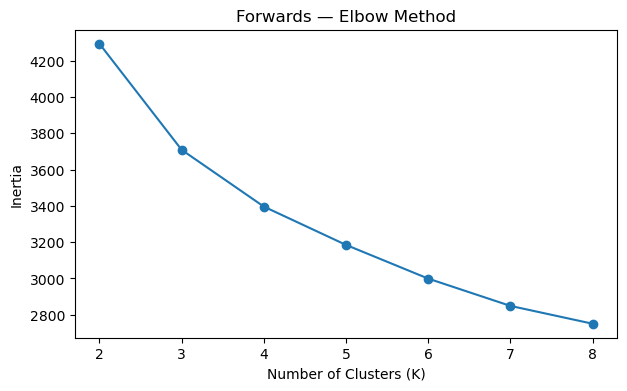

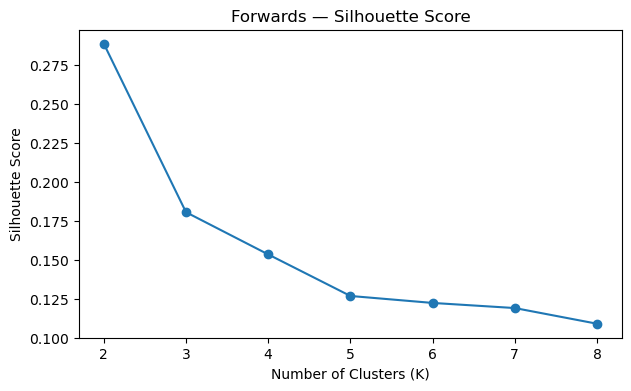

C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

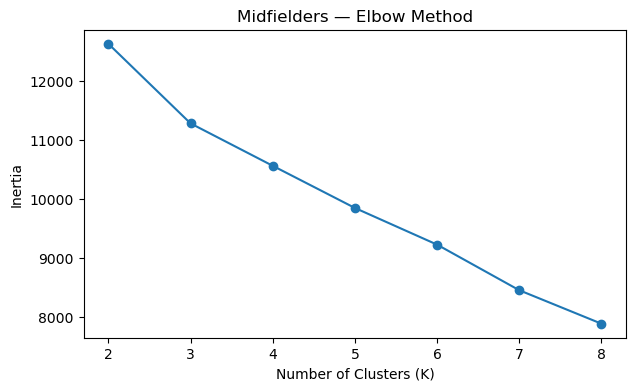

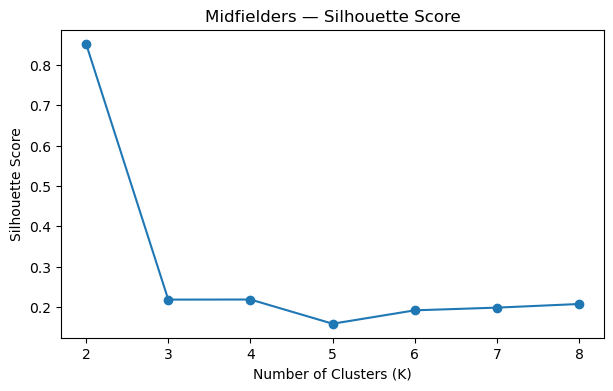

C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

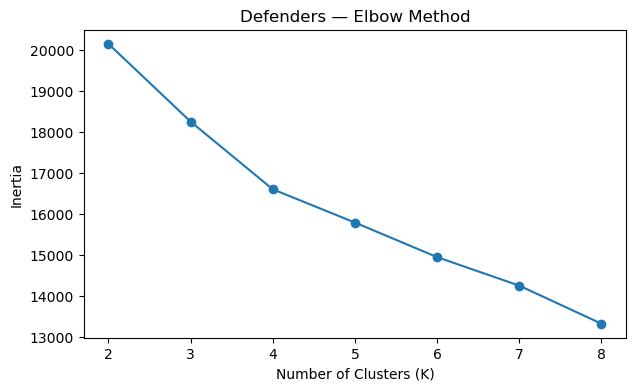

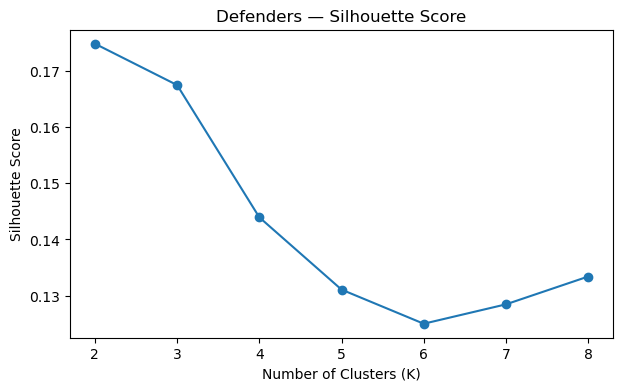

C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

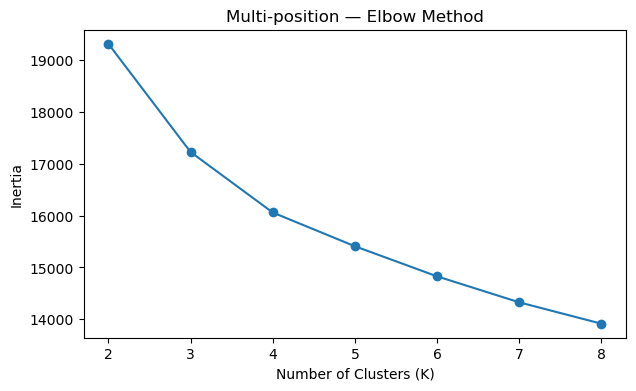

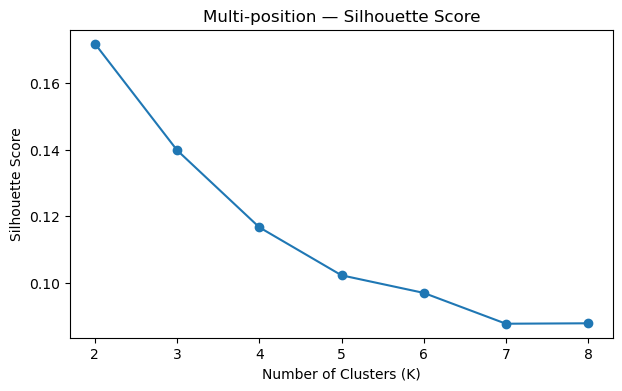

In [206]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# ==========================================
# FIND OPTIMAL NUMBER OF CLUSTERS
# ==========================================

cluster_results = {}

for name, X_scaled in scaled_datasets.items():

    inertias = []
    silhouettes = []
    k_values = range(2, 9)

    for k in k_values:

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = kmeans.fit_predict(X_scaled)

        inertias.append(kmeans.inertia_)
        silhouettes.append(
            silhouette_score(X_scaled, labels)
        )

    cluster_results[name] = {
        "k": list(k_values),
        "inertia": inertias,
        "silhouette": silhouettes
    }

    # ------------------------------
    # Elbow plot
    # ------------------------------

    plt.figure(figsize=(7, 4))

    plt.plot(
        k_values,
        inertias,
        marker='o'
    )

    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Inertia")
    plt.title(f"{name} — Elbow Method")
    plt.xticks(list(k_values))
    plt.show()

    # ------------------------------
    # Silhouette plot
    # ------------------------------

    plt.figure(figsize=(7, 4))

    plt.plot(
        k_values,
        silhouettes,
        marker='o'
    )

    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Silhouette Score")
    plt.title(f"{name} — Silhouette Score")
    plt.xticks(list(k_values))
    plt.show()

In [207]:
for name, result in cluster_results.items():

    print(f"\n{name}")
    print("-" * 50)

    for k, silhouette in zip(
        result["k"],
        result["silhouette"]
    ):
        print(
            f"K={k}: "
            f"Silhouette={silhouette:.4f}"
        )


Forwards
--------------------------------------------------
K=2: Silhouette=0.2885
K=3: Silhouette=0.1804
K=4: Silhouette=0.1534
K=5: Silhouette=0.1267
K=6: Silhouette=0.1222
K=7: Silhouette=0.1190
K=8: Silhouette=0.1089

Midfielders
--------------------------------------------------
K=2: Silhouette=0.8527
K=3: Silhouette=0.2182
K=4: Silhouette=0.2185
K=5: Silhouette=0.1584
K=6: Silhouette=0.1917
K=7: Silhouette=0.1984
K=8: Silhouette=0.2074

Defenders
--------------------------------------------------
K=2: Silhouette=0.1748
K=3: Silhouette=0.1675
K=4: Silhouette=0.1439
K=5: Silhouette=0.1311
K=6: Silhouette=0.1250
K=7: Silhouette=0.1285
K=8: Silhouette=0.1334

Multi-position
--------------------------------------------------
K=2: Silhouette=0.1718
K=3: Silhouette=0.1398
K=4: Silhouette=0.1167
K=5: Silhouette=0.1023
K=6: Silhouette=0.0970
K=7: Silhouette=0.0877
K=8: Silhouette=0.0879


In [208]:
from sklearn.cluster import KMeans

# ==========================================
# FINAL K-MEANS MODELS
# ==========================================

optimal_k = {
    "Forwards": 2,
    "Midfielders": 2,
    "Defenders": 2,
    "Multi-position": 2
}

kmeans_models = {}
cluster_labels = {}

for name, X_scaled in scaled_datasets.items():

    k = optimal_k[name]

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    kmeans_models[name] = model
    cluster_labels[name] = labels

    print(f"\n{name}")
    print("-" * 40)
    print("K:", k)
    print("Players:", len(labels))

    print("\nCluster sizes:")
    print(
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )

C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



Forwards
----------------------------------------
K: 2
Players: 227

Cluster sizes:
0     50
1    177
Name: count, dtype: int64

Midfielders
----------------------------------------
K: 2
Players: 573

Cluster sizes:
0    570
1      3
Name: count, dtype: int64


C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(



Defenders
----------------------------------------
K: 2
Players: 843

Cluster sizes:
0    480
1    363
Name: count, dtype: int64

Multi-position
----------------------------------------
K: 2
Players: 551

Cluster sizes:
0    214
1    337
Name: count, dtype: int64


C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


In [209]:
# ==========================================
# ADD CLUSTER LABELS TO DATASETS
# ==========================================

clustered_datasets = {}

for name, (df_data, features) in ml_datasets.items():

    df_clustered = df_data.copy()

    df_clustered["Cluster"] = cluster_labels[name]

    clustered_datasets[name] = df_clustered

    print(f"\n{name}")
    print("-" * 40)

    print(
        df_clustered[
            ["Player", "Cluster"]
        ].head()
    )


Forwards
----------------------------------------
            Player  Cluster
13  Matthis Abline        1
18   Tammy Abraham        1
23      Akor Adams        1
24       Che Adams        1
26    Junior Adamu        1

Midfielders
----------------------------------------
                Player  Cluster
11       Nabil Aberdin        0
12   Oliver Abildgaard        0
19  Federico Accornero        0
25         Tyler Adams        0
28      Martin Adeline        0

Defenders
----------------------------------------
                Player  Cluster
0           Max Aarons        1
2       Rodrigo Abajas        1
5     Yunis Abdelhamid        0
7  Mohamed Abdelmoneim        0
9      Saud Abdulhamid        1

Multi-position
----------------------------------------
               Player  Cluster
6       Himad Abdelli        0
8            Ali Abdi        0
15  Zakaria Aboukhlal        1
29      Karim Adeyemi        1
30      Simon Adingra        1


In [210]:
for name, df_data in clustered_datasets.items():

    print(f"\n{name}")
    print("-" * 40)

    print(
        df_data["Cluster"]
        .value_counts()
        .sort_index()
    )


Forwards
----------------------------------------
Cluster
0     50
1    177
Name: count, dtype: int64

Midfielders
----------------------------------------
Cluster
0    570
1      3
Name: count, dtype: int64

Defenders
----------------------------------------
Cluster
0    480
1    363
Name: count, dtype: int64

Multi-position
----------------------------------------
Cluster
0    214
1    337
Name: count, dtype: int64


In [211]:
# ==========================================
# CLUSTER PROFILES
# ==========================================

cluster_profiles = {}

for name, (df_data, features) in ml_datasets.items():

    df_clustered = clustered_datasets[name]

    profile = (
        df_clustered
        .groupby("Cluster")[features]
        .mean()
        .T
    )

    cluster_profiles[name] = profile

    print(f"\n{'='*70}")
    print(f"{name} — CLUSTER PROFILES")
    print(f"{'='*70}")

    print(profile.round(2))


Forwards — CLUSTER PROFILES
Cluster          0      1
Gls_p90       0.41   0.38
xG_p90        0.36   0.40
npxG_p90      0.31   0.36
G-xG          1.19  -0.15
G/SoT         0.34   0.36
Sh_p90        2.72   2.44
SoT_p90       1.08   0.95
SoT%         39.12  38.95
npxG/Sh       0.11   0.15
Ast_p90       0.26   0.10
xAG_p90       0.25   0.10
KP_p90        1.83   0.88
SCA_p90       4.04   2.09
GCA_p90       0.55   0.26
PrgP_p90      3.48   1.58
PrgC_p90      4.31   1.34
PrgR_p90      9.76   5.36
Carries_p90  30.98  16.83
CPA_p90       2.04   0.67
Succ%        43.00  37.08
AttPen_p90    5.60   4.52
Won_p90       0.67   2.41
Won%         37.51  41.81
Cmp%         75.11  69.36
xA            4.51   1.16

Midfielders — CLUSTER PROFILES
Cluster          0       1
Gls_p90       0.08    0.00
xG_p90        0.10    0.33
Ast_p90       0.08    0.00
xAG_p90       0.08    2.33
xA_p90        0.09    2.33
Cmp_p90      40.14  130.00
Cmp%         80.97   87.27
PrgP_p90      4.68   43.33
1/3_p90       4.02  

In [212]:
# ==========================================
# FIND TOP DIFFERENTIATING FEATURES
# ==========================================

for name, profile in cluster_profiles.items():

    print(f"\n{'='*60}")
    print(name)
    print(f"{'='*60}")

    # Difference between the two clusters
    diff = (profile[1] - profile[0]).abs()

    print("\nTop 10 differentiating features:")
    print(
        diff
        .sort_values(ascending=False)
        .head(10)
        .round(3)
    )


Forwards

Top 10 differentiating features:
Carries_p90    14.151
Succ%           5.929
Cmp%            5.751
PrgR_p90        4.399
Won%            4.293
xA              3.349
PrgC_p90        2.972
SCA_p90         1.951
PrgP_p90        1.902
Won_p90         1.739
dtype: float64

Midfielders

Top 10 differentiating features:
Touches_p90    129.733
Cmp_p90         89.857
Rec_p90         72.788
Carries_p90     70.218
PrgP_p90        38.656
SCA90           27.583
KP_p90          25.685
PrgC_p90        25.248
Succ%           16.711
1/3_p90         12.649
dtype: float64

Defenders

Top 10 differentiating features:
Won%           12.956
Cmp_p90        11.150
Succ%          10.315
Rec_p90         9.968
Cmp%            9.169
Carries_p90     8.448
Touches_p90     7.049
Def Pen_p90     4.533
Clr_p90         1.910
PrgC_p90        1.248
dtype: float64

Multi-position

Top 10 differentiating features:
Tkl%           12.477
Won%           11.590
Cmp_p90        11.103
Touches_p90    10.576
SoT%       

In [213]:
# ==========================================
# SHOW DIRECTION OF DIFFERENCE
# ==========================================

for name, profile in cluster_profiles.items():

    comparison = pd.DataFrame({
        "Cluster_0": profile[0],
        "Cluster_1": profile[1],
        "Difference": profile[1] - profile[0]
    })

    comparison["Absolute_Difference"] = comparison["Difference"].abs()

    print(f"\n{'='*70}")
    print(f"{name} — CLUSTER DIFFERENCES")
    print(f"{'='*70}")

    print(
        comparison
        .sort_values("Absolute_Difference", ascending=False)
        .head(15)
        .round(3)
    )


Forwards — CLUSTER DIFFERENCES
             Cluster_0  Cluster_1  Difference  Absolute_Difference
Carries_p90     30.985     16.834     -14.151               14.151
Succ%           43.004     37.075      -5.929                5.929
Cmp%            75.110     69.359      -5.751                5.751
PrgR_p90         9.756      5.358      -4.399                4.399
Won%            37.514     41.807       4.293                4.293
xA               4.512      1.163      -3.349                3.349
PrgC_p90         4.308      1.336      -2.972                2.972
SCA_p90          4.041      2.090      -1.951                1.951
PrgP_p90         3.483      1.580      -1.902                1.902
Won_p90          0.667      2.405       1.739                1.739
CPA_p90          2.043      0.669      -1.374                1.374
G-xG             1.192     -0.147      -1.339                1.339
AttPen_p90       5.597      4.521      -1.076                1.076
KP_p90           1.828      0.

In [214]:
archetype_names = {
    "Forwards": {
        0: "Progressive Forward",
        1: "Creative Forward"
    },

    "Midfielders": {
        0: "Defensive/Workhorse Midfielder",
        1: "Progressive Creator"
    },

    "Defenders": {
        0: "Ball-Playing Defender",
        1: "Defensive Defender"
    },

    "Multi-position": {
        0: "Defensive Utility Player",
        1: "Attacking Utility Player"
    }
}

print(archetype_names)

{'Forwards': {0: 'Progressive Forward', 1: 'Creative Forward'}, 'Midfielders': {0: 'Defensive/Workhorse Midfielder', 1: 'Progressive Creator'}, 'Defenders': {0: 'Ball-Playing Defender', 1: 'Defensive Defender'}, 'Multi-position': {0: 'Defensive Utility Player', 1: 'Attacking Utility Player'}}


In [215]:
from sklearn.preprocessing import StandardScaler

# ------------------------------------------
# PREPARE DATA FOR PLAYER SIMILARITY
# ------------------------------------------

similarity_data = {}

datasets = {
    "Forwards": df_forwards_ml_base,
    "Midfielders": df_midfielders_ml_base,
    "Defenders": df_defenders_ml_base,
    "Multi-position": df_multi_position_ml_base
}

feature_lists = {
    "Forwards": forward_ml_features,
    "Midfielders": midfielder_ml_features,
    "Defenders": defender_ml_features,
    "Multi-position": multi_ml_features
}

for position in datasets:

    df_temp = datasets[position].copy()
    features = feature_lists[position]

    # Keep only players and ML features
    X = df_temp[features].copy()

    # Standardize
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    similarity_data[position] = {
        "players": df_temp["Player"].values,
        "features": features,
        "X_scaled": X_scaled,
        "scaler": scaler
    }

    print(
        position,
        "→",
        X_scaled.shape
    )

ValueError: Input X contains infinity or a value too large for dtype('float64').

In [216]:
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# ==========================================
# PREPARE DATA FOR PLAYER SIMILARITY
# ==========================================

similarity_data = {}

datasets = {
    "Forwards": df_forwards_ml_base,
    "Midfielders": df_midfielders_ml_base,
    "Defenders": df_defenders_ml_base,
    "Multi-position": df_multi_position_ml_base
}

feature_lists = {
    "Forwards": forward_ml_features,
    "Midfielders": midfielder_ml_features,
    "Defenders": defender_ml_features,
    "Multi-position": multi_ml_features
}

for position in datasets:

    df_temp = datasets[position].copy()
    features = feature_lists[position]

    # Keep only required ML features
    X = df_temp[features].copy()

    # Identify rows containing non-finite values
    valid_rows = np.isfinite(X).all(axis=1)

    removed = (~valid_rows).sum()

    # Keep only valid players
    df_temp = df_temp.loc[valid_rows].copy()
    X = X.loc[valid_rows].copy()

    # Standardize
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    similarity_data[position] = {
        "players": df_temp["Player"].values,
        "features": features,
        "X_scaled": X_scaled,
        "scaler": scaler
    }

    print(
        f"{position}: "
        f"{len(df_temp)} valid players | "
        f"{removed} players excluded due to infinite values"
    )

Forwards: 357 valid players | 14 players excluded due to infinite values
Midfielders: 573 valid players | 0 players excluded due to infinite values
Defenders: 843 valid players | 0 players excluded due to infinite values
Multi-position: 551 valid players | 0 players excluded due to infinite values


In [217]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def find_similar_players(player_name, position, top_n=5):

    data = similarity_data[position]

    players = data["players"]
    X_scaled = data["X_scaled"]

    matches = np.where(players == player_name)[0]

    if len(matches) == 0:
        return f"Player '{player_name}' not found in {position} similarity dataset."

    player_idx = matches[0]

    similarities = cosine_similarity(
        X_scaled[player_idx].reshape(1, -1),
        X_scaled
    )[0]

    # Don't recommend the player himself
    similarities[player_idx] = -1

    top_indices = np.argsort(similarities)[::-1][:top_n]

    result = pd.DataFrame({
        "Player": players[top_indices],
        "Similarity": similarities[top_indices] * 100
    })

    result["Similarity"] = result["Similarity"].round(2)

    return result

In [218]:
for position, data in similarity_data.items():

    print(
        position,
        "| Players:", len(data["players"]),
        "| Features:", len(data["features"]),
        "| Infinite:", np.isinf(data["X_scaled"]).sum(),
        "| Missing:", np.isnan(data["X_scaled"]).sum()
    )

Forwards | Players: 357 | Features: 25 | Infinite: 0 | Missing: 0
Midfielders | Players: 573 | Features: 27 | Infinite: 0 | Missing: 0
Defenders | Players: 843 | Features: 27 | Infinite: 0 | Missing: 0
Multi-position | Players: 551 | Features: 43 | Infinite: 0 | Missing: 0


In [219]:
print(df_forwards_ml_base["Player"].head(20).tolist())

['Keyliane Abdallah', 'Matthis Abline', 'Tammy Abraham', 'Tammy Abraham', 'Akor Adams', 'Akor Adams', 'Che Adams', 'Junior Adamu', 'Junior Ajayi', 'Ludovic Ajorque', 'Chuba Akpom', 'Andreas Albers', 'Tadeo Allende', 'Jim Allevinah', 'Miguel Almirón', 'Julián Álvarez', 'Will Alves', 'Mohamed Amoura', 'Marcos André', 'Lorenzo Anghelè']


In [220]:
find_similar_players(
    "PLAYER NAME HERE",
    "Forwards",
    top_n=5
)

"Player 'PLAYER NAME HERE' not found in Forwards similarity dataset."

In [221]:
find_similar_players(
    "Keyliane Abdallah",
    "Forwards",
    top_n=5
)

"Player 'Keyliane Abdallah' not found in Forwards similarity dataset."

In [222]:
for position, data in similarity_data.items():
    players = pd.Series(data["players"])

    print(f"\n{position}")
    print("Total rows:", len(players))
    print("Unique players:", players.nunique())
    print("Duplicate rows:", players.duplicated().sum())
    


Forwards
Total rows: 357
Unique players: 347
Duplicate rows: 10

Midfielders
Total rows: 573
Unique players: 549
Duplicate rows: 24

Defenders
Total rows: 843
Unique players: 803
Duplicate rows: 40

Multi-position
Total rows: 551
Unique players: 546
Duplicate rows: 5


In [223]:
# ==========================================
# INSPECT DUPLICATE PLAYER RECORDS
# ==========================================

for position, df_temp in {
    "Forwards": df_forwards_ml_base,
    "Midfielders": df_midfielders_ml_base,
    "Defenders": df_defenders_ml_base,
    "Multi-position": df_multi_position_ml_base
}.items():

    duplicates = df_temp[
        df_temp["Player"].duplicated(keep=False)
    ].sort_values("Player")

    print(f"\n{'='*70}")
    print(position)
    print(f"{'='*70}")

    if len(duplicates) == 0:
        print("No duplicates")
    else:
        print(
            duplicates[
                ["Player", "Nation", "Squad", "Comp", "Min", "90s"]
            ].to_string(index=False)
        )


Forwards
             Player  Nation         Squad               Comp  Min  90s
         Akor Adams  ng NGA       Sevilla         es La Liga  134  1.5
         Akor Adams  ng NGA   Montpellier         fr Ligue 1 1075 11.9
Anastasios Douvikas  gr GRE          Como         it Serie A  580  6.4
Anastasios Douvikas  gr GRE    Celta Vigo         es La Liga  700  7.8
      Evan Ferguson  ie IRL      West Ham eng Premier League  156  1.7
      Evan Ferguson  ie IRL      Brighton eng Premier League  246  2.7
    Jesper Karlsson  se SWE         Lecce         it Serie A  495  5.5
    Jesper Karlsson  se SWE       Bologna         it Serie A  298  3.3
       Jordan Pefok  us USA  Union Berlin      de Bundesliga  908 10.1
       Jordan Pefok  us USA         Reims         fr Ligue 1  380  4.2
   Mama Samba Baldé  gw GNB         Brest         fr Ligue 1 1149 12.8
   Mama Samba Baldé  gw GNB          Lyon         fr Ligue 1   33  0.4
        Milan Đurić  ba BIH         Parma         it Serie A  268  

In [ ]:
# ==========================================
# CREATE ONE ML ROW PER PLAYER
# ==========================================

def aggregate_player_ml(df, features):

    df = df.copy()

    # Make sure infinite values don't break aggregation
    df[features] = df[features].replace([np.inf, -np.inf], np.nan)

    # Weight by minutes
    weights = df["90s"].fillna(0)

    rows = []

    for player, group in df.groupby("Player", sort=False):

        weight = group["90s"].fillna(0)

        row = {
            "Player": player,
            "Min": group["Min"].sum(),
            "90s": group["90s"].sum()
        }

        for feature in features:

            values = group[feature]

            valid = values.notna() & weight.notna() & (weight > 0)

            if valid.any():
                row[feature] = np.average(
                    values[valid],
                    weights=weight[valid]
                )
            else:
                row[feature] = np.nan

        rows.append(row)

    return pd.DataFrame(rows)

In [ ]:
# ==========================================
# AGGREGATE TRANSFER PLAYERS
# ==========================================

df_forwards_player = aggregate_player_ml(
    df_forwards_ml_base,
    forward_ml_features
)

df_midfielders_player = aggregate_player_ml(
    df_midfielders_ml_base,
    midfielder_ml_features
)

df_defenders_player = aggregate_player_ml(
    df_defenders_ml_base,
    defender_ml_features
)

df_multi_position_player = aggregate_player_ml(
    df_multi_position_ml_base,
    multi_ml_features
)

print("Forwards:", df_forwards_player.shape)
print("Midfielders:", df_midfielders_player.shape)
print("Defenders:", df_defenders_player.shape)
print("Multi-position:", df_multi_position_player.shape)

In [ ]:
for name, data in {
    "Forwards": df_forwards_player,
    "Midfielders": df_midfielders_player,
    "Defenders": df_defenders_player,
    "Multi-position": df_multi_position_player
}.items():

    print(
        f"{name}: "
        f"Rows={len(data)}, "
        f"Unique players={data['Player'].nunique()}, "
        f"Duplicates={data['Player'].duplicated().sum()}"
    )

In [227]:
import numpy as np
import pandas as pd

# ==========================================
# FAST PLAYER-LEVEL AGGREGATION
# ==========================================

def aggregate_player_ml_fast(df, features):

    data = df.copy()

    # Replace infinity with NaN
    data[features] = data[features].replace(
        [np.inf, -np.inf],
        np.nan
    )

    # 90s used as weights
    weights = data["90s"].fillna(0)

    # Group information
    grouped = data.groupby("Player", sort=False)

    # Basic player information
    result = grouped[["Min", "90s"]].sum()

    # Calculate weighted averages for each feature
    for feature in features:

        weighted_values = data[feature] * weights

        numerator = weighted_values.groupby(data["Player"]).sum(
            min_count=1
        )

        denominator = (
            weights.where(data[feature].notna(), 0)
            .groupby(data["Player"])
            .sum()
        )

        result[feature] = numerator / denominator

    result = result.reset_index()

    return result

In [228]:
# ==========================================
# PLAYER-SEASON DATASETS
# ==========================================

df_forwards_player = aggregate_player_ml_fast(
    df_forwards_ml_base,
    forward_ml_features
)

df_midfielders_player = aggregate_player_ml_fast(
    df_midfielders_ml_base,
    midfielder_ml_features
)

df_defenders_player = aggregate_player_ml_fast(
    df_defenders_ml_base,
    defender_ml_features
)

df_multi_position_player = aggregate_player_ml_fast(
    df_multi_position_ml_base,
    multi_ml_features
)

In [229]:
# ==========================================
# VERIFY PLAYER-LEVEL DATASETS
# ==========================================

player_datasets = {
    "Forwards": df_forwards_player,
    "Midfielders": df_midfielders_player,
    "Defenders": df_defenders_player,
    "Multi-position": df_multi_position_player
}

for name, data in player_datasets.items():

    print(
        f"{name}: "
        f"Rows={len(data)}, "
        f"Unique players={data['Player'].nunique()}, "
        f"Duplicates={data['Player'].duplicated().sum()}, "
        f"Missing={data.isna().sum().sum()}, "
        f"Infinite={np.isinf(data.select_dtypes(include=np.number)).sum().sum()}"
    )

Forwards: Rows=359, Unique players=359, Duplicates=0, Missing=325, Infinite=0
Midfielders: Rows=549, Unique players=549, Duplicates=0, Missing=0, Infinite=0
Defenders: Rows=803, Unique players=803, Duplicates=0, Missing=0, Infinite=0
Multi-position: Rows=546, Unique players=546, Duplicates=0, Missing=0, Infinite=0


In [230]:
# ==========================================
# CHECK FORWARD MISSING PLAYERS
# ==========================================

forward_missing_counts = (
    df_forwards_player[forward_ml_features]
    .isna()
    .sum(axis=1)
)

problem_forwards = df_forwards_player.loc[
    forward_missing_counts > 0,
    ["Player", "Min", "90s"]
].copy()

problem_forwards["Missing_Features"] = forward_missing_counts[
    forward_missing_counts > 0
].values

print(problem_forwards.to_string(index=False))

              Player  Min  90s  Missing_Features
   Keyliane Abdallah    3  0.0                25
       Tadeo Allende    2  0.0                25
          Will Alves    1  0.0                25
      Kandet Diawara    4  0.0                25
        Sérigné Diop    4  0.0                25
  Arijon Ibrahimović    1  0.0                25
    Jonah Kusi-Asare    3  0.0                25
       Aaron Malouda    2  0.0                25
            Maurides    2  0.0                25
    Remy Rees-Dottin    1  0.0                25
Zain Silcott-Duberry    1  0.0                25
      Ayanda Sishuba    3  0.0                25
        Daniel Yáñez    2  0.0                25


In [231]:
# ==========================================
# REMOVE PLAYERS WITH 0 90s
# ==========================================

before = len(df_forwards_player)

df_forwards_player = df_forwards_player[
    df_forwards_player["90s"] > 0
].copy()

after = len(df_forwards_player)

print("Forwards before:", before)
print("Forwards after :", after)
print("Players removed:", before - after)

Forwards before: 359
Forwards after : 346
Players removed: 13


In [232]:
# ==========================================
# FINAL ML DATA VALIDATION
# ==========================================

final_player_datasets = {
    "Forwards": (df_forwards_player, forward_ml_features),
    "Midfielders": (df_midfielders_player, midfielder_ml_features),
    "Defenders": (df_defenders_player, defender_ml_features),
    "Multi-position": (df_multi_position_player, multi_ml_features)
}

for name, (data, features) in final_player_datasets.items():

    X = data[features]

    print(f"\n{name}")
    print("-" * 40)
    print("Players:", len(data))
    print("Features:", len(features))
    print("Missing:", X.isna().sum().sum())
    print("Infinite:", np.isinf(X).sum().sum())
    print("Duplicate players:", data["Player"].duplicated().sum())


Forwards
----------------------------------------
Players: 346
Features: 25
Missing: 0
Infinite: 0
Duplicate players: 0

Midfielders
----------------------------------------
Players: 549
Features: 27
Missing: 0
Infinite: 0
Duplicate players: 0

Defenders
----------------------------------------
Players: 803
Features: 27
Missing: 0
Infinite: 0
Duplicate players: 0

Multi-position
----------------------------------------
Players: 546
Features: 43
Missing: 0
Infinite: 0
Duplicate players: 0


In [233]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# ==========================================
# FINAL PLAYER-LEVEL CLUSTERING
# ==========================================

cluster_data = {
    "Forwards": (df_forwards_player, forward_ml_features),
    "Midfielders": (df_midfielders_player, midfielder_ml_features),
    "Defenders": (df_defenders_player, defender_ml_features),
    "Multi-position": (df_multi_position_player, multi_ml_features)
}

cluster_results = {}

for position, (df_data, features) in cluster_data.items():

    X = df_data[features].copy()

    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # K=2 based on our earlier silhouette analysis
    kmeans = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    # Save everything
    result = df_data.copy()
    result["Cluster"] = labels

    cluster_results[position] = {
        "data": result,
        "features": features,
        "X_scaled": X_scaled,
        "scaler": scaler,
        "model": kmeans
    }

    print(
        f"{position}: "
        f"{len(result)} players | "
        f"Cluster 0 = {(labels == 0).sum()} | "
        f"Cluster 1 = {(labels == 1).sum()}"
    )

C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Forwards: 346 players | Cluster 0 = 255 | Cluster 1 = 91
Midfielders: 549 players | Cluster 0 = 546 | Cluster 1 = 3


C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


Defenders: 803 players | Cluster 0 = 457 | Cluster 1 = 346


C:\Users\pious\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


Multi-position: 546 players | Cluster 0 = 334 | Cluster 1 = 212


In [234]:
for position, result in cluster_results.items():

    print(f"\n{position}")
    print(
        result["data"]["Cluster"]
        .value_counts()
        .sort_index()
    )


Forwards
Cluster
0    255
1     91
Name: count, dtype: int64

Midfielders
Cluster
0    546
1      3
Name: count, dtype: int64

Defenders
Cluster
0    457
1    346
Name: count, dtype: int64

Multi-position
Cluster
0    334
1    212
Name: count, dtype: int64


In [235]:
# ==========================================
# CLUSTER PROFILES
# ==========================================

cluster_profiles = {}

for position, result in cluster_results.items():

    data = result["data"]
    features = result["features"]

    profile = (
        data
        .groupby("Cluster")[features]
        .mean()
    )

    cluster_profiles[position] = profile

    print(f"\n{'='*60}")
    print(position)
    print(f"{'='*60}")

    print(profile.round(2))


Forwards
         Gls_p90  xG_p90  npxG_p90  G-xG  G/SoT  Sh_p90  SoT_p90   SoT%  \
Cluster                                                                   
0           0.33    0.41      0.38 -0.16   0.30    2.55     0.92  34.00   
1           0.22    0.24      0.22  0.54   0.19    2.49     0.78  28.39   

         npxG/Sh  Ast_p90  ...  PrgC_p90  PrgR_p90  Carries_p90  CPA_p90  \
Cluster                    ...                                             
0           0.14     0.08  ...      1.32      5.49        17.31     0.62   
1           0.07     0.15  ...      4.13     10.50        33.58     2.16   

         Succ%  AttPen_p90  Won_p90   Won%   Cmp%    xA  
Cluster                                                  
0        32.82        4.58     2.38  40.83  67.52  0.90  
1        35.25        6.01     0.55  23.86  76.70  2.38  

[2 rows x 25 columns]

Midfielders
         Gls_p90  xG_p90  Ast_p90  xAG_p90  xA_p90  Cmp_p90   Cmp%  PrgP_p90  \
Cluster                             

In [236]:
from sklearn.metrics.pairwise import cosine_similarity

# ==========================================
# PLAYER SIMILARITY ENGINE
# ==========================================

similarity_data = {}

for position, result in cluster_results.items():

    data = result["data"].copy()
    X_scaled = result["X_scaled"]

    similarity_matrix = cosine_similarity(X_scaled)

    similarity_data[position] = {
        "players": data["Player"].reset_index(drop=True),
        "matrix": similarity_matrix,
        "data": data,
        "features": result["features"]
    }

    print(
        f"{position}: "
        f"{len(data)} players × {len(data)} players"
    )

Forwards: 346 players × 346 players
Midfielders: 549 players × 549 players
Defenders: 803 players × 803 players
Multi-position: 546 players × 546 players


In [237]:
def find_similar_players(player_name, position, top_n=5):

    if position not in similarity_data:
        return f"Position '{position}' not found."

    data = similarity_data[position]

    players = data["players"]

    # Find player
    matches = players[
        players.str.lower() == player_name.lower()
    ]

    if len(matches) == 0:
        return f"Player '{player_name}' not found in {position}."

    player_index = matches.index[0]

    # Similarity scores
    scores = data["matrix"][player_index]

    similarity_df = pd.DataFrame({
        "Player": players,
        "Similarity": scores
    })

    # Remove the player himself
    similarity_df = similarity_df[
        similarity_df["Player"].str.lower() != player_name.lower()
    ]

    return (
        similarity_df
        .sort_values("Similarity", ascending=False)
        .head(top_n)
        .reset_index(drop=True)
    )

In [240]:
print(df_forwards_player["Player"].head(20).tolist())

['Matthis Abline', 'Tammy Abraham', 'Akor Adams', 'Che Adams', 'Junior Adamu', 'Junior Ajayi', 'Ludovic Ajorque', 'Chuba Akpom', 'Andreas Albers', 'Jim Allevinah', 'Miguel Almirón', 'Julián Álvarez', 'Mohamed Amoura', 'Marcos André', 'Lorenzo Anghelè', 'Leandro Antonetti', 'Michail Antonio', 'Antony', 'Cameron Archer', 'Adu Ares']


In [241]:
print(
    find_similar_players(
        "Julián Álvarez",
        "Forwards",
        top_n=5
    )
)

            Player  Similarity
0   Alexander Isak    0.855880
1     Bryan Mbeumo    0.854492
2    Kylian Mbappé    0.815114
3       Harry Kane    0.801335
4  Ousmane Dembélé    0.792722


In [242]:
def scout_replacements(player_name, position, top_n=10, min_similarity=0.60):

    if position not in similarity_data:
        return f"Position '{position}' not found."

    data = similarity_data[position]

    players = data["players"]
    player_data = data["data"]

    # Find target player
    matches = players[
        players.str.lower() == player_name.lower()
    ]

    if len(matches) == 0:
        return f"Player '{player_name}' not found in {position}."

    target_idx = matches.index[0]

    # Similarity scores
    scores = data["matrix"][target_idx]

    recommendations = player_data[
        ["Player", "Min", "90s", "Cluster"]
    ].copy()

    recommendations["Similarity"] = scores

    # Remove target player
    recommendations = recommendations[
        recommendations["Player"].str.lower() != player_name.lower()
    ]

    # Minimum similarity
    recommendations = recommendations[
        recommendations["Similarity"] >= min_similarity
    ]

    # Rank
    recommendations = (
        recommendations
        .sort_values("Similarity", ascending=False)
        .head(top_n)
        .reset_index(drop=True)
    )

    recommendations["Similarity"] = (
        recommendations["Similarity"] * 100
    ).round(1)

    return recommendations

In [243]:
scout_replacements(
    "Julián Álvarez",
    "Forwards",
    top_n=10
)

,Player,Min,90s,Cluster,Similarity
0,Alexander Isak,2756,30.6,0,85.6
1,Bryan Mbeumo,3414,37.9,1,85.4
2,Kylian Mbappé,2907,32.3,1,81.5
3,Harry Kane,2381,26.5,0,80.1
4,Ousmane Dembélé,1730,19.2,1,79.3
5,Luis Díaz,2399,26.7,1,79.1
6,Marcus Thuram,2200,24.4,0,79.0
7,Mohamed Salah,3371,37.5,1,78.9
8,Cody Gakpo,1935,21.5,1,75.1
9,Harvey Barnes,1755,19.5,1,73.8


In [244]:
# ==========================================
# CONFIGURABLE SCOUTING ENGINE
# ==========================================

priority_features = {
    "Forwards": {
        "Scoring": [
            "Gls_p90", "G-PK_p90", "xG_p90", "npxG_p90"
        ],
        "Creation": [
            "Ast_p90", "xAG_p90", "KP_p90", "SCA_p90", "GCA_p90"
        ],
        "Progression": [
            "PrgP_p90", "PrgC_p90", "PrgR_p90"
        ],
        "Possession": [
            "Carries_p90", "Touches_p90", "Rec_p90"
        ]
    },

    "Midfielders": {
        "Scoring": [
            "Gls_p90", "xG_p90"
        ],
        "Creation": [
            "Ast_p90", "xAG_p90", "xA_p90",
            "KP_p90", "PPA_p90", "SCA90", "GCA90"
        ],
        "Progression": [
            "PrgP_p90", "PrgC_p90", "1/3_p90"
        ],
        "Possession": [
            "Touches_p90", "Carries_p90", "Rec_p90"
        ],
        "Defending": [
            "Tkl_p90", "TklW_p90", "Int_p90",
            "Tkl+Int_p90", "Blocks_p90"
        ]
    },

    "Defenders": {
        "Defending": [
            "Tkl_p90", "TklW_p90", "Int_p90",
            "Tkl+Int_p90", "Blocks_p90", "Clr_p90"
        ],
        "Progression": [
            "PrgP_p90", "PrgC_p90", "1/3_p90"
        ],
        "Possession": [
            "Touches_p90", "Carries_p90", "Rec_p90"
        ],
        "Creation": [
            "Ast_p90", "xAG_p90"
        ]
    },

    "Multi-position": {
        "Scoring": [
            "Gls_p90", "xG_p90", "npxG_p90"
        ],
        "Creation": [
            "Ast_p90", "xAG_p90", "xA_p90",
            "KP_p90", "PPA_p90", "SCA_p90"
        ],
        "Progression": [
            "PrgP_p90", "PrgC_p90", "PrgR_p90"
        ],
        "Possession": [
            "Touches_p90", "Carries_p90", "Rec_p90"
        ],
        "Defending": [
            "Tkl_p90", "TklW_p90", "Int_p90",
            "Tkl+Int_p90", "Blocks_p90"
        ]
    }
}

In [245]:
def scout_with_priorities(
    player_name,
    position,
    priorities,
    top_n=10,
    similarity_weight=0.60
):

    if position not in similarity_data:
        return f"Position '{position}' not found."

    data = similarity_data[position]

    players = data["players"]
    player_data = data["data"].copy()

    # Find target player
    matches = players[
        players.str.lower() == player_name.lower()
    ]

    if len(matches) == 0:
        return f"Player '{player_name}' not found in {position}."

    target_idx = matches.index[0]

    # Similarity
    similarity = data["matrix"][target_idx]

    player_data["Similarity"] = similarity

    # Remove target player
    player_data = player_data[
        player_data["Player"].str.lower() != player_name.lower()
    ].copy()

    # ------------------------------------------
    # Determine selected feature groups
    # ------------------------------------------

    available_groups = priority_features[position]

    selected = []

    for group, weight in priorities.items():

        if group not in available_groups:
            continue

        valid_features = [
            f for f in available_groups[group]
            if f in player_data.columns
        ]

        if len(valid_features) > 0:
            selected.append(
                (group, weight, valid_features)
            )

    if len(selected) == 0:
        return "No valid priority features found."

    # ------------------------------------------
    # Calculate weighted performance score
    # ------------------------------------------

    total_weight = sum(weight for _, weight, _ in selected)

    performance_score = pd.Series(
        0.0,
        index=player_data.index
    )

    for group, weight, features in selected:

        # Average percentile rank of selected features
        group_score = (
            player_data[features]
            .rank(pct=True)
            .mean(axis=1)
        )

        performance_score += (
            group_score * (weight / total_weight)
        )

    player_data["Performance_Score"] = performance_score

    # ------------------------------------------
    # Final scouting score
    # ------------------------------------------

    player_data["Scouting_Score"] = (
        similarity_weight * player_data["Similarity"]
        +
        (1 - similarity_weight) * player_data["Performance_Score"]
    )

    # ------------------------------------------
    # Output
    # ------------------------------------------

    result = (
        player_data[
            [
                "Player",
                "Min",
                "90s",
                "Cluster",
                "Similarity",
                "Performance_Score",
                "Scouting_Score"
            ]
        ]
        .sort_values("Scouting_Score", ascending=False)
        .head(top_n)
        .reset_index(drop=True)
    )

    result["Similarity"] = (
        result["Similarity"] * 100
    ).round(1)

    result["Performance_Score"] = (
        result["Performance_Score"] * 100
    ).round(1)

    result["Scouting_Score"] = (
        result["Scouting_Score"] * 100
    ).round(1)

    return result

In [246]:
scout_with_priorities(
    "Julián Álvarez",
    "Forwards",
    priorities={
        "Scoring": 0.60,
        "Creation": 0.40
    },
    top_n=10
)

,Player,Min,90s,Cluster,Similarity,Performance_Score,Scouting_Score
0,Ousmane Dembélé,1730,19.2,1,79.3,96.5,86.1
1,Alexander Isak,2756,30.6,0,85.6,83.8,84.9
2,Kylian Mbappé,2907,32.3,1,81.5,87.8,84.0
3,Harry Kane,2381,26.5,0,80.1,89.3,83.8
4,Mohamed Salah,3371,37.5,1,78.9,90.9,83.7
5,Luis Díaz,2399,26.7,1,79.1,80.5,79.7
6,Marcus Thuram,2200,24.4,0,79.0,77.9,78.6
7,Omar Marmoush,1448,16.1,1,71.2,89.3,78.5
8,Bryan Mbeumo,3414,37.9,1,85.4,67.7,78.4
9,Leroy Sané,1637,18.2,1,69.1,86.7,76.1


In [247]:
scout_with_priorities(
    "Julián Álvarez",
    "Forwards",
    priorities={
        "Scoring": 0.20,
        "Creation": 0.50,
        "Progression": 0.30
    },
    top_n=10
)

,Player,Min,90s,Cluster,Similarity,Performance_Score,Scouting_Score
0,Ousmane Dembélé,1730,19.2,1,79.3,96.4,86.1
1,Mohamed Salah,3371,37.5,1,78.9,92.3,84.3
2,Kylian Mbappé,2907,32.3,1,81.5,86.0,83.3
3,Bryan Mbeumo,3414,37.9,1,85.4,78.9,82.8
4,Alexander Isak,2756,30.6,0,85.6,77.4,82.3
5,Luis Díaz,2399,26.7,1,79.1,85.4,81.6
6,Harry Kane,2381,26.5,0,80.1,78.4,79.4
7,Omar Marmoush,1448,16.1,1,71.2,89.0,78.4
8,Marcus Thuram,2200,24.4,0,79.0,76.6,78.1
9,Leroy Sané,1637,18.2,1,69.1,88.6,76.9


In [248]:
# ==========================================
# PREPARE FINAL DASHBOARD DATA
# ==========================================

dashboard_data = {
    "Forwards": {
        "players": df_forwards_player.copy(),
        "features": forward_ml_features,
        "cluster": cluster_results["Forwards"],
        "similarity": similarity_data["Forwards"]
    },

    "Midfielders": {
        "players": df_midfielders_player.copy(),
        "features": midfielder_ml_features,
        "cluster": cluster_results["Midfielders"],
        "similarity": similarity_data["Midfielders"]
    },

    "Defenders": {
        "players": df_defenders_player.copy(),
        "features": defender_ml_features,
        "cluster": cluster_results["Defenders"],
        "similarity": similarity_data["Defenders"]
    },

    "Multi-position": {
        "players": df_multi_position_player.copy(),
        "features": multi_ml_features,
        "cluster": cluster_results["Multi-position"],
        "similarity": similarity_data["Multi-position"]
    }
}

print("Dashboard data prepared successfully.")

for position, data in dashboard_data.items():

    print(
        f"{position}: "
        f"{len(data['players'])} players | "
        f"{len(data['features'])} features"
    )

Dashboard data prepared successfully.
Forwards: 346 players | 25 features
Midfielders: 549 players | 27 features
Defenders: 803 players | 27 features
Multi-position: 546 players | 43 features


In [249]:
import joblib

# ==========================================
# SAVE FINAL FOOTBALL INTELLIGENCE ENGINE
# ==========================================

engine_bundle = {
    "dashboard_data": dashboard_data,
    "similarity_data": similarity_data,
    "cluster_results": cluster_results,
    "priority_features": priority_features
}

joblib.dump(
    engine_bundle,
    "football_intelligence_engine.pkl"
)

print("✅ Football Intelligence Engine saved!")
print("File: football_intelligence_engine.pkl")

✅ Football Intelligence Engine saved!
File: football_intelligence_engine.pkl


In [250]:
import os

print(
    "File exists:",
    os.path.exists("football_intelligence_engine.pkl")
)

print(
    "File size:",
    round(os.path.getsize("football_intelligence_engine.pkl") / (1024 * 1024), 2),
    "MB"
)

File exists: True
File size: 12.84 MB
